# 08 — Bayesian Optimiser — M-Sand SDL

Proposes the **next concrete trials** to cast, and a **portfolio** of mixes that are
predicted to meet the requirement at the lowest **cost** and **embodied carbon**.

| Needs, in this folder | Made by |
|---|---|
| `is_rules.py` and the `IS_codes/` PDFs | `00_is_codes_layer.ipynb` |
| `strength_model.joblib`, `workability_model.joblib` | `03_Modelling_audited.ipynb` |
| `plant_transfer.json` (plant-to-plant spread, PPC test) | `03b_plant_transfer_check.ipynb` |
| `01_RAW_dataset.csv` (optional — the measured mixes already proven) | the data sheet |

**Install:** `pip install scikit-learn==1.5.2 scipy pandas numpy matplotlib joblib`
(the models were saved with scikit-learn 1.5.2; a different version can change them).

### Units — as the Indian Standards write them

| Quantity | Unit | Basis |
|---|---|---|
| every material | kg per m³ of concrete | aggregates at saturated surface dry (IS 10262 cl 3.1) |
| water | kg/m³ of **free** water | IS 456 Table 5 "free water-cement ratio" |
| w/c, w/b | ratio of masses | IS 10262 cl 3.1, 3.2 |
| fly ash, GGBS, admixture | % by mass of binder | |
| strength | N/mm² (= MPa) at 28 days, 150 mm cube | IS 456 Table 2 Note 1 |
| slump | mm, nearest 5 mm | IS 1199 (Part 2) cl 4.3 |
| cost / carbon | Rs per m³ / kg CO₂e per m³ | project arithmetic [PC] |

### How the pieces fit

| Layer | Job | Kind of rule |
|---|---|---|
| 00 → `is_rules.py` | every Indian Standard limit | `[IS]` standard |
| 03 → `*.joblib` | predicts strength and slump, with uncertainty | `[ML]` model |
| this notebook | searches mixes, prices them, picks the next trials | `[PC]` project method |

This notebook defines **no** IS value. It calls `is_rules`. It also never trains a model:
it loads the ones 03 validated. After a trial is cast and measured, the result goes back
into the data, 03 is re-run, and this notebook is re-run. **That** is the Bayesian loop.

## 0. Setup — IS rules imported, engine defined

Run these cells once, then continue from section 1.

In [81]:
# ---- IS code layer: imported, not redefined ----
# Every IS constant lives in 00_is_codes_layer.ipynb, which writes is_rules.py.
from is_rules import (
    verify_sources,
    target_mean_strength,        # IS 10262 cl 4.2 / IS 456 cl 9.2.2
    water_content,               # IS 10262 Table 4 (Sec 2) / Table 7 (Sec 3)
    coarse_aggregate_volume,     # IS 10262 Table 5 / Table 10 + cl 5.5.1
    table5_lookup,               # IS 456 Table 5 + Table 6
    compliance_gate,             # IS 456 cl 8 durability + cl 8.2.4.2 + IS 10262 + IS 9103
    slump_acceptance_band,       # IS 4926 cl 6.2.1
    slump_reading_valid,         # IS 1199 (Part 2) cl 4.3
    sample_test_result,          # IS 456 cl 15.3 / 15.4
    check_cement, check_fly_ash, check_ggbs, check_aggregate,   # soundness + conformity
    IS10262_TABLE3_AIR,          # IS 10262 Table 3
    CEMENT_TYPES,
    IS456_CL_8_2_4_2_MAX_CEMENT,      # IS 456 cl 8.2.4.2: 450 kg/m3 of CEMENT only
    established_standard_deviation,   # IS 10262 cl 4.2.1.1 / 4.2.1.2
    standard_deviation_check,         # IS 10262 cl 4.2.1.1 (c)
    acceptance_is456,                 # IS 456 cl 16.1 / Table 11
)

# Prove the frozen PDFs are the ones the values were read from, before using any.
verify_sources(strict=True)

{'IS 456:2000': ('ok',
  'Fourth Revision, Tenth Reprint April 2007, including Amendments No. 1 and 2'),
 'IS 10262:2019': ('ok', 'Second Revision'),
 'IS 383:2016': ('ok', 'Third Revision, January 2016'),
 'IS 9103:1999': ('ok', '-'),
 'IS 4926:2003': ('ok', 'Second Revision'),
 'IS 3812 (Part 1):2013': ('ok', 'Third Revision'),
 'IS 16714:2018': ('ok', '2018 (no revision number printed)'),
 'IS 1199 (Part 2):2018': ('ok', 'First Revision'),
 'IS 1489 (Part 1):1991': ('ok',
  'Third Revision, with Amendments No. 1 (1991), 2 (1993), 3 (2000), 4 (2005), 5 (2009)')}

In [82]:
# ---- optimiser engine ----
"""
STRUCTURE
  03 models (joblib)   predict strength and slump, each with uncertainty
  IS 10262             seeds the search with one code-derived mix
  IS 456 / 4926 / 1199 constraints, via is_rules (durability gate, slump band, validity)
  cost, carbon, waste  deterministic arithmetic -- no model
  acquisition          expected hypervolume improvement, feasibility drawn JOINTLY (MC)
Strength and slump are REQUIREMENTS. Cost and carbon are the objectives.
"""
import json
import numpy as np
import pandas as pd
import joblib
import warnings
from dataclasses import dataclass, field
from typing import Optional
from scipy.stats import norm
from itertools import product

warnings.filterwarnings("ignore")


# =============================================================================
# 1. REQUIREMENT -- what the engineer asks for
# =============================================================================
@dataclass
class Requirement:
    grade: str = "M30"
    exposure: str = "severe"            # IS 456 Table 3 / Table 5 class
    reinforced: bool = True             # RCC -> 'rcc'; PCC -> 'pcc'
    slump_target_mm: float = 110.0      # measured by IS 1199 (Part 2) slump test
    msa_mm: int = 20                    # nominal maximum aggregate size
    site_control: str = "good"          # IS 10262 Table 2 Note 1
    established_s: Optional[float] = None   # IS 10262 cl 4.2.1.1 (needs >= 30 results)
    n_results: Optional[int] = None
    sulphate_class: Optional[int] = None    # IS 456 Table 4, if soil/water is tested
    sea_water: bool = False                 # IS 456 cl 8.2.8
    freeze_thaw: bool = False               # IS 456 cl 8.2.2.3
    wearing_surface: bool = False           # IS 383 cl 5.4
    p_strength_min: float = 0.95        # [PC] P(mean strength >= target mean)
    p_slump_min: float = 0.80           # [PC] P(slump inside the IS 4926 band)

    @property
    def fck(self) -> float:
        """Characteristic strength. IS 456 cl 6.1.1."""
        return float(self.grade.upper().lstrip("M"))

    @property
    def target(self) -> dict:
        """IS 10262 cl 4.2 target MEAN strength f'ck = max(fck + 1.65 S, fck + X)."""
        return target_mean_strength(self.grade, established_s=self.established_s,
                                    n_results=self.n_results, site_control=self.site_control)

    @property
    def slump_band(self):
        """IS 4926 cl 6.2.1: +/-25 mm or +/-1/3 of the specified value, whichever is less."""
        b = slump_acceptance_band(self.slump_target_mm)
        return (b["low"], b["high"])

    @property
    def use(self) -> str:
        return "rcc" if self.reinforced else "pcc"


# =============================================================================
# 2. MATERIALS -- what is in the silos, with its certificates and rates
# =============================================================================
# =============================================================================
# 2b. MATERIAL RATES -- market survey supplied by the project team (Sep 2026)
# =============================================================================
# [PC] Rates are PROJECT INPUT, not an Indian Standard. Ranges as supplied; nothing here is
#      invented. Rs per tonne unless stated. A plant using this should replace them with
#      its own purchase rates.
COST_SURVEY = {
    "OPC":          {"range": (7200, 8600), "unit": "Rs/t", "note": "Rs 360-430 per 50 kg bag (UltraTech, ACC, Ambuja, JK ...)"},
    "crushed_sand": {"range": (900, 1400),  "unit": "Rs/t", "note": "M-sand; or Rs 28,000-40,000 per 20-22 t truck"},
    "admixture":    {"range": (45000, 120000), "unit": "Rs/t", "note": "superplasticiser Rs 45-120 per kg (or litre) by brand/type"},
    "flyash":       {"range": (1000, 2200), "unit": "Rs/t", "note": "fly ash"},
    "ggbs":         {"range": (2500, 4200), "unit": "Rs/t", "note": "GGBS"},
    "natural_sand": {"range": (2000, 3500), "unit": "Rs/t", "note": "river sand; or Rs 55,000-80,000 per truck"},
}
# Not in the survey. PPC and coarse aggregate are DERIVED [EI] from a surveyed material with
# a price RATIO read from one published market listing (infralens.in, Mumbai
# dealer-to-retail, 12 Aug 2026 [S]): PPC Rs 408 vs OPC Rs 450 per bag; 20 mm aggregate
# Rs 1,273-1,894 vs M-sand Rs 2,200-2,800 per t (mid-points). Only the RATIO is borrowed,
# so the survey's own price level is kept. Replace with real quotes when available.
COST_DERIVED = {"PPC": ("OPC", 408 / 450),
                "coarse": ("crushed_sand", ((1273 + 1894) / 2) / ((2200 + 2800) / 2))}
COST_NOT_SURVEYED = {"water": 30}          # [U] placeholder; ~Rs 5 per m3, negligible

TRUCK_T = (20.0, 22.0)                       # t per truck, from the M-sand line of the survey
DELIVERY = {                                 # Rs per tonne delivered, as (low, high)
    "OPC": (5 * 20, 20 * 20),                # Rs 5-20 per 50 kg bag = Rs 100-400 per t
    "bulk": (1500 / TRUCK_T[1], 6000 / TRUCK_T[0]),   # Rs 1,500-6,000 per 20-22 t truck
    "admixture": (0.0, 0.0),                 # "often included for bulk orders"
}
DELIVERY_GROUP = {"OPC": "OPC", "PPC": "OPC", "crushed_sand": "bulk", "coarse": "bulk",
                  "flyash": "bulk", "ggbs": "bulk", "natural_sand": "bulk", "admixture": "admixture"}
BULK_DISCOUNT = {                            # fraction off, or Rs/t off, as (low, high)
    "OPC": ("pct", (0.02, 0.08)),
    "PPC": ("pct", (0.02, 0.08)),            # [EI] PPC given the survey's cement discount
    "crushed_sand": ("rs", (50, 150)),
    "flyash": ("pct", (0.05, 0.10)), "ggbs": ("pct", (0.05, 0.10)),
    "admixture": ("pct", (0.05, 0.15)),
}


def rates_from_survey(basis: str = "mid", bulk: bool = True, delivered: bool = True) -> dict:
    """Rs per tonne for every material, from COST_SURVEY [PC].
    basis 'low' | 'mid' | 'high' picks the cheap end, the middle or the dear end of EVERY
    range at once (price, discount and freight), so 'low'..'high' brackets the true rate.
    bulk: an RMC plant buys by the truckload, so the survey's bulk discounts apply.
    delivered: adds the survey's freight (per bag for cement, per truck for bulk)."""
    f = {"low": 0.0, "mid": 0.5, "high": 1.0}[basis]
    pick = lambda lo_hi, rev=False: lo_hi[0] + (lo_hi[1] - lo_hi[0]) * ((1 - f) if rev else f)
    out = {}
    survey = dict(COST_SURVEY)
    for k, (base, ratio) in COST_DERIVED.items():               # derived ranges [EI]
        lo, hi = COST_SURVEY[base]["range"]
        survey[k] = {"range": (lo * ratio, hi * ratio)}
    for k, v in survey.items():
        r = pick(v["range"])
        if bulk and k in BULK_DISCOUNT:
            kind, rng_ = BULK_DISCOUNT[k]
            d = pick(rng_, rev=True)             # cheap end = biggest discount
            r = r * (1 - d) if kind == "pct" else r - d
        if delivered:
            r += pick(DELIVERY[DELIVERY_GROUP[k]])
        out[k] = round(r, 1)
    out.update(COST_NOT_SURVEYED)
    return out


# Carbon, kg CO2e per tonne, cradle-to-gate (A1-A3). Source per factor.
CARBON_FACTORS = {
    "OPC":          (870, "India Construction Materials Database (IFC/EDGE 2017) Table 14 [S]"),
    "PPC":          (680, "same [S]"),
    "flyash":       (6.3, "same [S]"),
    "crushed_sand": (4.1, "same, 'sand' [S]"),
    "natural_sand": (4.1, "same, 'sand' [S]"),
    "coarse":       (4.1, "same, 'aggregates' [S]"),
    "admixture":    (690, "EFCA superplasticiser environmental declaration, 2002, Europe [S]"),
    "ggbs":         (80,  "NOT VERIFIED -- the Indian database lists a negative value [U]"),
    "water":        (0.3, "NOT VERIFIED, negligible [U]"),
}


@dataclass
class Materials:
    """Everything here is plant-specific. Rates: the project's market survey (mid-range,
    bulk, delivered) [PC], PPC and coarse aggregate derived by a published price ratio [EI].
    Carbon: published factors [S] (CARBON_FACTORS). Replace both with the plant's purchase
    rates and its suppliers' EPDs before any real use."""
    cement_type: str = "PPC"                        # 'OPC' or 'PPC' (IS 456 cl 5.1)
    ppc_fly_ash_declared_pct: Optional[float] = None   # None = GENERAL: IS 1489 upper limit 35 %
                                                       # (a plant may pass its cl 9.1 declared %)
    has_flyash: bool = True
    has_ggbs: bool = False
    natural_sand_frac: float = 0.0                  # 0 = all crushed (M-sand)
    # specific gravities [U]; IS 10262 Annex A uses PPC 2.88, CA 2.74, FA 2.65, SP 1.145
    sg: dict = field(default_factory=lambda: {"OPC": 3.15, "PPC": 2.88, "flyash": 2.20,
                                              "ggbs": 2.90, "coarse": 2.74, "fine": 2.65,
                                              "admixture": 1.145})
    admixture_dosage_range_pct: Optional[tuple] = None   # IS 9103 cl 10.2, from the supplier
    admixture_solids_pct: Optional[float] = None    # None -> count all admixture as water
    sp_water_reduction_pct: float = 20.0            # [PC] plant value, used only for the seed
    sand_zone: str = "II"
    # certificates (dicts in the is_rules key names); None = not supplied
    cement_cert: Optional[dict] = None
    flyash_cert: Optional[dict] = None
    ggbs_cert: Optional[dict] = None
    coarse_props: Optional[dict] = None
    fine_props: Optional[dict] = None
    chloride_pct: Optional[dict] = None     # % Cl by mass of each constituent (IS 456 Table 7)
    so3_pct: Optional[dict] = None          # % water-soluble SO3 of each constituent (8.2.5.3)
    # rates (Rs per tonne): project market survey, mid-range, bulk, delivered [PC]
    #   PPC, coarse aggregate and water are NOT in the survey -> placeholders [U]
    # carbon (kg CO2e per tonne): CARBON_FACTORS, each with its source
    cost: dict = field(default_factory=lambda: rates_from_survey("mid"))
    carbon: dict = field(default_factory=lambda: {k: v[0] for k, v in CARBON_FACTORS.items()})
    loss_pct: dict = field(default_factory=lambda: {"binder": 0.0, "aggregate": 0.0})  # [PC]
    trial_volume_m3: float = 0.04       # [PC] one lab trial: 6 cubes + slump + margin


# =============================================================================
# 3. THE 03 MODELS -- features and prediction copied from 03, then vectorised
# =============================================================================
# mix_features() and predict() below are copied from 03_Modelling_audited.ipynb unchanged.
# Section 1 of this notebook proves it: it reproduces 03's printed example to 1e-9.
SG_FEAT = {'cement': 3.15, 'flyash': 2.2, 'ggbs': 2.9, 'other_scm': 2.3}   # 03's feature SGs


def mix_features(mix):
    """Raw mix (kg/m3) -> the exact features used in training (section 2 of 03)."""
    c, fa, gg, osc = mix['cement'], mix.get('flyash', 0), mix.get('ggbs', 0), mix.get('other_scm', 0)
    w = mix['water']; coarse = mix['coarse_agg']
    fine = mix.get('crushed_sand', 0) + mix.get('natural_sand', 0)
    binder = c + fa + gg + osc
    return {'water_batched': w, 'wb': w / binder, 'log_wb': np.log(w / binder),
            'fa_frac': fa / binder, 'ggbs_frac': gg / binder, 'osc_frac': osc / binder,
            'scm_frac': (fa + gg + osc) / binder,
            'paste_vol': (c/SG_FEAT['cement'] + fa/SG_FEAT['flyash'] + gg/SG_FEAT['ggbs']
                          + osc/SG_FEAT['other_scm'] + w) / 1000,
            'sp_pct': mix.get('admixture', 0) / binder * 100,
            'fine_frac': fine / (fine + coarse),
            'nat_sand_frac': mix.get('natural_sand', 0) / fine,
            'msa': mix.get('msa', 20),
            'is_ppc': 1.0 if str(mix.get('cement_type', 'OPC')).upper().startswith('PPC') else 0.0}


def predict(model, mix):
    """03's single-mix predictor, unchanged."""
    f = mix_features(mix); mus, sds = [], []
    for m in model['members']:
        Z = m['scaler'].transform(np.array([[f[k] for k in m['feats']]]))
        if m['kind'] == 'ridge':
            mus.append(m['model'].predict(Z)[0]); continue
        mu, sd = m['model'].predict(Z, return_std=True)
        mus.append(mu[0] * m['ysd'] + m['ym']); sds.append(np.sqrt((sd[0] * m['ysd'])**2 + model['noise']**2))
    mu, sd = np.mean(mus), np.mean(sds); q = model['q90']
    outside = [k for k, (lo, hi) in model['feature_range'].items() if not lo <= f[k] <= hi]
    return {'prediction': float(np.exp(mu)), 'log_sd': float(sd),
            'lower_90': float(np.exp(mu - q * sd)), 'upper_90': float(np.exp(mu + q * sd)),
            'outside_training_range': outside}


def predict_batch(model, mixes):
    """Vectorised version of predict(). Also returns sd_model: the GP members' own spread
    WITHOUT the replicate-noise term, for judging a MEAN (see Section 5 of the engine).
    `mixes` may also be a DataFrame of features already computed (used by 08b)."""
    F = mixes if isinstance(mixes, pd.DataFrame) else pd.DataFrame([mix_features(m) for m in mixes])
    mus, sds, sdm = [], [], []
    for m in model['members']:
        Z = m['scaler'].transform(F[m['feats']].values)
        if m['kind'] == 'ridge':
            mus.append(m['model'].predict(Z)); continue
        mu, sd = m['model'].predict(Z, return_std=True)
        mus.append(mu * m['ysd'] + m['ym'])
        sds.append(np.sqrt((sd * m['ysd'])**2 + model['noise']**2))
        sdm.append(sd * m['ysd'])
    mu, sd, sd_model = np.mean(mus, 0), np.mean(sds, 0), np.mean(sdm, 0)
    inside = np.ones(len(F), bool)
    for k, (lo, hi) in model['feature_range'].items():
        inside &= (F[k].values >= lo) & (F[k].values <= hi)
    return {"mu": mu, "sd": sd, "sd_model": sd_model, "inside": inside, "features": F}


def predict_corr(model, mixes):
    """Correlation between candidates' predicted means (GP members' posterior covariance,
    averaged in log units, then normalised). Two similar recipes are likely to be wrong in
    the same direction; the acquisition needs that to value a BATCH correctly
    (Daulton et al. 2020, 2021 -- qEHVI / qNEHVI integrate over the JOINT posterior).
    Each member's kernel ends in a WhiteKernel, and sklearn puts that white term on the
    diagonal of the predictive covariance. It is independent per recipe, so it is split
    off: returns R (correlation of the smooth part) and frac (share of each recipe's
    variance that is the smooth, shareable part). Marginals are left to predict_batch.
    `mixes` may also be a DataFrame of features already computed (used by 08b)."""
    F = mixes if isinstance(mixes, pd.DataFrame) else pd.DataFrame([mix_features(m) for m in mixes])
    covs, whites = [], []
    for m in model['members']:
        if m['kind'] == 'ridge':
            continue
        Z = m['scaler'].transform(F[m['feats']].values)
        _, cov = m['model'].predict(Z, return_cov=True)
        wn = m['model'].kernel_.k2.noise_level                      # C*Matern + White
        covs.append(cov * m['ysd'] ** 2)
        whites.append(wn * m['ysd'] ** 2)
    C = np.mean(covs, 0)
    tot = np.clip(np.diag(C), 1e-12, None)
    L = C - np.eye(len(C)) * np.mean(whites)                          # smooth (latent) part
    lat = np.clip(np.diag(L), 1e-12, None)
    R = L / np.sqrt(np.outer(lat, lat))
    np.fill_diagonal(R, 1.0)
    return R, np.clip(lat / tot, 0.0, 1.0)


def to_model_cement(mix: dict, ppc_x_pct: float) -> dict:
    """[EI][ML] PPC is Portland clinker ground with fly ash (IS 1489 Part 1). The models are
    fed PPC as OPC + that fly ash, at x = the IS 1489 upper limit (the same 35 % the IS gate
    uses), with is_ppc = 0. 03b tested this: a model that never saw PPC then predicts the
    PPC plant's strength with a small bias. OPC mixes pass through unchanged."""
    if str(mix.get("cement_type", "OPC")).upper().startswith("PPC"):
        x = ppc_x_pct / 100.0
        m = dict(mix)
        m["flyash"] = mix.get("flyash", 0.0) + mix["cement"] * x
        m["cement"] = mix["cement"] * (1 - x)
        m["cement_type"] = "OPC"
        return m
    return mix


def data_domain(path: str, ppc_x_pct: float) -> dict:
    """Ranges of the mixes the models actually saw, ALL plants pooled, with every PPC mix
    re-expressed as OPC + fly ash first (same mapping as the model input) [PC].
    Combined with 03's per-feature range, a mix is scored only inside both."""
    try:
        d = pd.read_csv(path, low_memory=False)
    except FileNotFoundError:
        return {}
    n = lambda c: pd.to_numeric(d[c], errors="coerce").fillna(0)
    ppc = d.cement_type.astype(str).str.upper().str.startswith("PPC")
    cem = n("cement") * np.where(ppc, 1 - ppc_x_pct / 100.0, 1.0)
    fa = n("flyash") + n("cement") * np.where(ppc, ppc_x_pct / 100.0, 0.0)
    b = cem + fa + n("ggbs") + n("other_scm")
    f = pd.DataFrame({"flyash_frac": fa / b, "ggbs_frac": n("ggbs") / b,
                      "wb_ratio": n("water_batched") / b, "sp_pct_binder": n("admixture1") / b * 100,
                      "binder_kg_m3": b, "water_kg_m3": n("water_batched")})[b > 0]
    dom = {k: (float(f[k].min()), float(f[k].max())) for k in f.columns}
    dom["_ppc_x"] = ppc_x_pct            # carried for the bounds; not a range
    return dom


def inside_domain(model_mix: dict, dom: dict) -> bool:
    if not dom:
        return True
    m = model_mix
    binder = m["cement"] + m["flyash"] + m["ggbs"] + m.get("other_scm", 0.0)
    v = {"flyash_frac": m["flyash"] / binder, "ggbs_frac": m["ggbs"] / binder,
         "wb_ratio": m["water"] / binder, "sp_pct_binder": m["admixture"] / binder * 100,
         "binder_kg_m3": binder, "water_kg_m3": m["water"]}
    return all(dom[k][0] - 1e-9 <= v[k] <= dom[k][1] + 1e-9 for k in v if k in dom)


# =============================================================================
# 3b. PLANT EFFECT -- the general model, adjusted to a plant as its results arrive
# =============================================================================
def early_age_ratio(path: str) -> Optional[dict]:
    """7-day -> 28-day strength, learned from the data [ML][PC].
    [IS] IS 456 cl 15.1.1: 7-day compressive tests are OPTIONAL, "to get a relatively
         quicker idea of the quality of concrete"; "the values should be arrived at based on
         actual testing"; "in all cases, the 28 days compressive strength ... shall alone be
         the criterion for acceptance or rejection of the concrete."
    So a 7-day result may STEER the next experiment, never accept a mix.
    Uses samples with both ages (each age = mean of its cubes). The spread is plant-weighted:
    within-plant variance + between-plant variance of the plant means, so a plant the data
    has never seen gets the full uncertainty."""
    try:
        d = pd.read_csv(path, low_memory=False)
        c7 = d[[f"cube_7d_{j}" for j in (1, 2, 3)]].apply(pd.to_numeric, errors="coerce").mean(axis=1)
        c28 = d[[f"cube_28d_{j}" for j in (1, 2, 3)]].apply(pd.to_numeric, errors="coerce").mean(axis=1)
    except (FileNotFoundError, KeyError):
        return None
    ok = (c7 > 0) & (c28 > 0)
    if ok.sum() < 10:
        return None
    r = pd.DataFrame({"plant": d.loc[ok, "plant_lab_id"].astype(str), "r": np.log(c28[ok] / c7[ok])})
    g = r.groupby("plant").r.agg(["mean", "var", "count"])
    g = g[g["count"] >= 2]
    within = float(g["var"].mean())
    between = float(g["mean"].var(ddof=1)) if len(g) > 1 else within
    return {"mean_log": float(g["mean"].mean()), "sd_log": float(np.sqrt(within + between)),
            "n_samples": int(ok.sum()), "n_plants": int(len(g)),
            "per_plant": {k: (round(float(np.exp(v["mean"])), 3), round(float(np.sqrt(v["var"])), 3), int(v["count"]))
                          for k, v in g.iterrows()}}


def plant_offset(model: dict, tau_log: float, results: list, measured_key: str,
                 ppc_x_pct: float, early: Optional[dict] = None) -> dict:
    """Normal-normal update of one plant's offset (log scale) [S].
    Prior: offset ~ N(0, tau^2), tau from 03b (leave-one-plant-out spread).
    Each result r_i = log(measured_i) - model mean, with its own noise variance s_i^2:
      a 28-day result: s_i^2 = 03's replicate noise^2;
      a 7-day-only result (strength): converted with early_age_ratio(), s_i^2 = noise^2 +
      the ratio's variance -- it counts, but less than a 28-day result.
    Posterior precision = 1/tau^2 + sum 1/s_i^2; offset = (sum r_i/s_i^2) / precision.
    With only 28-day results this is exactly the old formula mean(r) k/(k + lam).
    With no results (a new plant) the offset is 0 and the full tau^2 is added."""
    rs, vals, extra = [], [], []
    for r in (results or []):
        if r.get(measured_key) is not None:
            rs.append(r); vals.append(float(r[measured_key])); extra.append(0.0)
        elif measured_key == "fc_28d" and early and r.get("fc_7d") is not None:
            rs.append(r); vals.append(float(r["fc_7d"]) * np.exp(early["mean_log"]))
            extra.append(early["sd_log"] ** 2)
    if not rs:
        return {"offset": 0.0, "var": tau_log ** 2, "k": 0, "k_28d": 0, "k_7d_only": 0}
    mixes = [to_model_cement(r["mix"], ppc_x_pct) for r in rs]
    mu = predict_batch(model, mixes)["mu"]
    out = offset_update(np.log(vals) - mu, model["noise"] ** 2 + np.array(extra), tau_log)
    out.update({"k_28d": int(sum(e == 0 for e in extra)), "k_7d_only": int(sum(e > 0 for e in extra))})
    return out


def trial_key(r: dict) -> tuple:
    """Identity of a proposed trial: plant, requirement and the batch quantities (0.1 kg)."""
    q = ("cement_kg_m3", "flyash_kg_m3", "ggbs_kg_m3", "water_kg_m3", "admixture_kg_m3",
         "crushed_sand_kg_m3", "natural_sand_kg_m3", "coarse_agg_kg_m3")
    return (str(r.get("plant_id")), str(r.get("grade")), str(r.get("exposure")),
            str(r.get("cement_type"))) + tuple(round(float(r.get(k, 0) or 0), 1) for k in q)


def plant_results_from_log(path: str, plant_id: str) -> list:
    """Cast trials of THIS plant from the prospective trial log -> PLANT_RESULTS entries.
    Only rows accepted for casting and with a measured value count (project rule)."""
    import os
    if not os.path.exists(path):
        return []
    L = pd.read_csv(path)
    L = L[(L.get("plant_id").astype(str) == str(plant_id)) &
          (L.get("review_decision").astype(str).str.lower() == "accept")]
    out, used = [], set()
    num = lambda r, c: pd.to_numeric(r.get(c), errors="coerce")
    for _, r in L.iterrows():
        key = trial_key(r.to_dict())
        if key in used:                     # the same cast trial logged twice counts once
            continue
        fc28, fc7, sl = num(r, "measured_fc_28d_mpa"), num(r, "measured_fc_7d_mpa"), num(r, "measured_slump_mm")
        if not any(np.isfinite(v) for v in (fc28, fc7, sl)):
            continue
        mix = {"cement": r.cement_kg_m3, "flyash": r.flyash_kg_m3, "ggbs": r.ggbs_kg_m3,
               "other_scm": 0.0, "water": r.water_kg_m3, "coarse_agg": r.coarse_agg_kg_m3,
               "crushed_sand": r.crushed_sand_kg_m3, "natural_sand": r.natural_sand_kg_m3,
               "admixture": r.admixture_kg_m3, "msa": r.get("msa_mm", 20), "cement_type": r.cement_type}
        e = {"mix": mix}
        if np.isfinite(fc28): e["fc_28d"] = float(fc28)
        elif np.isfinite(fc7): e["fc_7d"] = float(fc7)
        if np.isfinite(sl): e["slump_mm"] = float(sl)
        out.append(e); used.add(key)
    return out


def offset_update(resid, s2, tau_log) -> dict:
    """The normal-normal core of plant_offset(): residuals (log) with noise variances s2."""
    resid, s2 = np.atleast_1d(resid), np.atleast_1d(s2)
    if len(resid) == 0:
        return {"offset": 0.0, "var": tau_log ** 2, "k": 0}
    prec = 1.0 / tau_log ** 2 + np.sum(1.0 / s2)
    return {"offset": float(np.sum(resid / s2) / prec), "var": float(1.0 / prec), "k": len(resid)}


# =============================================================================
# 4. DECISION VARIABLES -- only what the optimiser may choose
# =============================================================================
# [PC] Search box only, used when no measured data file is found. It is NOT a limit:
#      IS sets no cap on total cementitious (IS 10262 Annex D uses 535 kg/m3). With data,
#      the box shrinks to the measured binder range below. Cement alone > 450 is stopped
#      by the gate (IS 456 cl 8.2.4.2) unless special consideration is recorded.
BINDER_SEARCH_MAX_NO_DATA = 600.0


def decision_bounds(req: Requirement, mat: Materials, sm: dict, wm: dict, domain: dict = None):
    """Bounds = IS-derived limits intersected with the range 03's models were trained on,
    and with the range measured in the data (all plants). Returns [(name, low, high, why)]."""
    lim = table5_lookup(req.exposure, req.use, req.msa_mm)
    wb_hi = min(lim["max_free_wc"], float(np.exp(sm["feature_range"]["log_wb"][1])))
    fa_hi = sm["feature_range"]["fa_frac"][1] if mat.has_flyash else 0.0
    if mat.cement_type.upper() == "PPC" and domain:
        # PPC reaches the model as OPC + x fly ash, so ADDED fly ash f must keep the
        # total x + f(1 - x) inside what the models saw [PC]
        x = domain.get("_ppc_x", 35.0) / 100.0
        tot = min(fa_hi, domain["flyash_frac"][1]) if "flyash_frac" in domain else fa_hi
        fa_hi = max(0.0, (tot - x) / (1 - x)) if mat.has_flyash else 0.0
    gg_hi = sm["feature_range"]["ggbs_frac"][1] if mat.has_ggbs else 0.0
    sp_lo, sp_hi = 0.0, min(sm["feature_range"]["sp_pct"][1], wm["feature_range"]["sp_pct"][1])
    if mat.admixture_dosage_range_pct is not None:
        sp_lo, sp_hi = max(sp_lo, mat.admixture_dosage_range_pct[0]), min(sp_hi, mat.admixture_dosage_range_pct[1])
    ff_lo = max(sm["feature_range"]["fine_frac"][0], wm["feature_range"]["fine_frac"][0])
    ff_hi = min(sm["feature_range"]["fine_frac"][1], wm["feature_range"]["fine_frac"][1])
    out = [
        ("binder_kg_m3", lim["min_cement_kg_m3"],
         domain["binder_kg_m3"][1] if domain and "binder_kg_m3" in domain else BINDER_SEARCH_MAX_NO_DATA,
         "IS 456 Table 5 minimum .. measured data range (no IS cap on the SUM; cement "
         "alone <= 450 is checked by the gate, IS 456 cl 8.2.4.2)"),
        ("wb_ratio",     0.25, wb_hi,
         "[PC] floor .. IS 456 Table 5 max w/c (w/b can never exceed it)"),
        ("flyash_frac",  0.0,  fa_hi, "03 training range (PPC: total fly ash incl. the 35 % inside); 0 if none in stock"),
        ("ggbs_frac",    0.0,  gg_hi, "03 training range; 0 if no GGBS in stock"),
        ("sp_pct_binder", sp_lo, sp_hi, "03 range, cut to the IS 9103 cl 10.2 declared range"),
        ("fine_frac_of_agg", ff_lo, ff_hi, "03 training range (both models)"),
    ]
    r = {k: v for k, v in (domain or {}).items()
         if k in ("binder_kg_m3", "wb_ratio", "sp_pct_binder")}   # unchanged by the PPC mapping
    if r:                      # shrink to what was measured, all plants [PC]
        out = [(n, max(lo, r[n][0]) if n in r else lo, min(hi, r[n][1]) if n in r else hi,
                why + (" ∩ measured range" if n in r else ""))
               for n, lo, hi, why in out]
        out = [(n, lo, max(lo, hi), why) for n, lo, hi, why in out]
    return out


def decode(x, req: Requirement, mat: Materials) -> Optional[dict]:
    """Decision vector -> a complete batch by the IS 10262 cl 5.7 absolute-volume method."""
    binder, wb, fa_f, gg_f, sp_pct, fine_f = [float(v) for v in x]
    if fa_f + gg_f >= 0.95:
        return None
    cement = binder * (1 - fa_f - gg_f)
    flyash, ggbs = binder * fa_f, binder * gg_f
    water = binder * wb
    adm = binder * sp_pct / 100.0
    if req.msa_mm not in IS10262_TABLE3_AIR:
        raise KeyError(f"IS 10262 Table 3 prints no air value for {req.msa_mm} mm")
    air = IS10262_TABLE3_AIR[req.msa_mm] / 100.0
    sg = mat.sg
    v_paste = (cement / sg[mat.cement_type] + flyash / sg["flyash"] + ggbs / sg["ggbs"]
               + water + adm / sg["admixture"]) / 1000.0
    v_agg = 1.0 - v_paste - air
    if v_agg <= 0.40:                      # [PC] a mix that is mostly paste is not concrete
        return None
    agg = v_agg * 1000.0 / (fine_f / sg["fine"] + (1 - fine_f) / sg["coarse"])
    fine, coarse = agg * fine_f, agg * (1 - fine_f)
    nat = fine * mat.natural_sand_frac
    solids = 1.0 if mat.admixture_solids_pct is None else mat.admixture_solids_pct / 100.0
    free_water_gate = water + (adm * (1 - solids) if mat.admixture_solids_pct is not None else adm)
    vol = v_paste + air + fine / sg["fine"] / 1000 + coarse / sg["coarse"] / 1000
    return {"cement_kg_m3": cement, "flyash_kg_m3": flyash, "ggbs_kg_m3": ggbs,
            "water_kg_m3": water, "admixture_kg_m3": adm, "binder_kg_m3": binder,
            "crushed_sand_kg_m3": fine - nat, "natural_sand_kg_m3": nat,
            "fine_agg_kg_m3": fine, "coarse_agg_kg_m3": coarse,
            "wb_ratio": wb, "sp_pct_binder": sp_pct, "fine_frac_of_agg": fine_f,
            "free_water_for_gate": free_water_gate, "volume_m3": vol,
            # the 03 model's input names
            "_model_mix": {"cement": cement, "flyash": flyash, "ggbs": ggbs, "other_scm": 0.0,
                           "water": water, "coarse_agg": coarse, "crushed_sand": fine - nat,
                           "natural_sand": nat, "admixture": adm, "msa": req.msa_mm,
                           "cement_type": mat.cement_type}}


# =============================================================================
# 5. COST, CARBON, WASTE -- deterministic arithmetic, no model
# =============================================================================
def cost_carbon(mix: dict, mat: Materials):
    """Rs/m3 and kg CO2e/m3. The cement line is priced by cement TYPE (OPC and PPC differ
    in price and, a lot, in carbon). Plant losses are added per material group [PC]."""
    lb, la = 1 + mat.loss_pct["binder"] / 100.0, 1 + mat.loss_pct["aggregate"] / 100.0
    q = {mat.cement_type: mix["cement_kg_m3"] * lb, "flyash": mix["flyash_kg_m3"] * lb,
         "ggbs": mix["ggbs_kg_m3"] * lb, "crushed_sand": mix["crushed_sand_kg_m3"] * la,
         "natural_sand": mix["natural_sand_kg_m3"] * la, "coarse": mix["coarse_agg_kg_m3"] * la,
         "admixture": mix["admixture_kg_m3"], "water": mix["water_kg_m3"]}
    cost = sum(v / 1000.0 * mat.cost[k] for k, v in q.items())
    carbon = sum(v / 1000.0 * mat.carbon[k] for k, v in q.items())
    return cost, carbon


def expected_trial_waste(cost_m3: float, p_feasible: float, mat: Materials) -> float:
    """[PC] Rs of material expected to be wasted by casting this mix as a trial: the trial
    batch cost times the chance it fails the requirement. This is the quantity the SDL
    exists to reduce."""
    return (1.0 - p_feasible) * mat.trial_volume_m3 * cost_m3


# =============================================================================
# 6. PROBABILISTIC CONSTRAINTS
# =============================================================================
Z90 = norm.ppf(0.95)       # 1.645: the raw 90 % two-sided multiplier


def p_mean_strength_ok(mu, sd_model, q90, target_mean, plant_var=0.0):
    """P(the mix's MEAN strength >= IS 10262 target mean f'ck).
    [EI] f'ck already carries the production margin (1.65 S), so only the model's
         uncertainty about the mean is used here -- adding batch scatter again would count
         the same risk twice. [PC] sd is widened by 03's conformal factor q90 / 1.645."""
    s = np.maximum(np.sqrt((sd_model * q90 / Z90) ** 2 + plant_var), 1e-9)
    return 1.0 - norm.cdf((np.log(target_mean) - mu) / s)


def p_batch_strength_ok(mu, sd, q90, fck, plant_var=0.0):
    """P(a single batch >= fck), using the full predictive spread (reported, not a filter).
    [IS] IS 456 cl 6.1.1: not more than 5 % of results below fck."""
    s = np.maximum(np.sqrt((sd * q90 / Z90) ** 2 + plant_var), 1e-9)
    return 1.0 - norm.cdf((np.log(fck) - mu) / s)


def p_slump_ok(mu, sd, q90, band, plant_var=0.0):
    """P(one batch's slump inside the IS 4926 cl 6.2.1 band). Two-sided."""
    lo, hi = band
    s = np.maximum(np.sqrt((sd * q90 / Z90) ** 2 + plant_var), 1e-9)
    return norm.cdf((np.log(hi) - mu) / s) - norm.cdf((np.log(lo) - mu) / s)


# =============================================================================
# 6b. JOINT DRAWS AND BATCH SELECTION -- shared by 08 and the 08b benchmark
# =============================================================================
def draw_joint(model, mixes, offset: dict, n_samples: int, rng, with_noise: bool):
    """Monte Carlo draws (log scale) of the model's value for every candidate AT ONCE:
    GP smooth part correlated between recipes, GP white part and (optionally) replicate
    noise independent, plant offset shared by all. Each marginal equals the one used for
    the P_ numbers (sd widened by 03's conformal factor q90 / 1.645)."""
    p = predict_batch(model, mixes)
    R, frac = predict_corr(model, mixes)
    w, V = np.linalg.eigh(R)
    L = V * np.sqrt(np.clip(w, 0, None))
    k = model["q90"] / Z90
    z = rng.standard_normal((n_samples, len(R))) @ L.T
    u = rng.standard_normal((n_samples, len(R)))
    e0 = rng.standard_normal((n_samples, 1))
    g = p["sd_model"] * k
    x = p["mu"] + offset["offset"] + g * (np.sqrt(frac) * z + np.sqrt(1 - frac) * u) + e0 * np.sqrt(offset["var"])
    if with_noise:
        x = x + rng.standard_normal((n_samples, len(R))) * np.sqrt(np.clip(p["sd"] ** 2 - p["sd_model"] ** 2, 0, None)) * k
    return x


def select_batch(pts, S, front0, ref, q, min_gain=0.0):
    """Greedy batch of q: each pick maximises E[hypervolume gain], summed over every
    pass/fail pattern of the earlier picks, weighted by P(pattern AND this pick passes),
    estimated from the success draws S (n_samples x n_candidates, bool).
    Stops early when the best expected gain is not above min_gain (stopping rule)."""
    picks, scores = [], []
    for _ in range(q):
        acq = np.zeros(len(pts))
        for combo in product((False, True), repeat=len(picks)):
            pat = np.all(S[:, picks] == np.array(combo), axis=1) if picks else np.ones(len(S), bool)
            if not pat.any():
                continue
            F = np.vstack([front0] + [pts[p][None] for p, c in zip(picks, combo) if c]) \
                if (len(front0) or any(combo)) else np.empty((0, 2))
            base = hv2d(F, ref)
            hvi = np.array([hv2d(np.vstack([F, p[None]]), ref) - base for p in pts])
            acq += hvi * S[pat].sum(0) / len(S)
        acq[picks] = -1
        k = int(np.argmax(acq))
        if acq[k] <= max(min_gain, 0.0):
            break
        picks.append(k); scores.append(float(acq[k]))
    return picks, scores


# [PC] Stopping rule, declared BEFORE testing: stop proposing when the best expected
#      hypervolume gain is below 1 % of the hypervolume already achieved by measured mixes.
#      The multi-objective analogue of EGO's rule, "if the expected improvement is less
#      than 1% of the best current function value ... we stop" (Jones, Schonlau & Welch,
#      J. Global Optim. 13, 1998).
# [PC] Safe-first: while any candidate has P(feasible) >= half the required probability
#      (0.475 for 0.95), only those are considered; when none is left, every candidate is
#      considered, still under the 1 % stopping rule. Chosen in 08b (Test 3) among rules
#      fixed before the test, by the project's first objective -- fewer wasted trials --
#      then by finding the cheapest passing mix: it keeps the old rule's low waste and
#      early gains and removes its premature stop. Pure constrained EHVI (no tier) finds
#      the cheapest pass more often but fails ~3 more trials in the first 8. Both remain
#      available (safe_first=False).
STOP_REL_EHVI = 0.01


# =============================================================================
# 7. THE OPTIMISER
# =============================================================================
FUNNEL_STEPS = ["sampled", "valid volumes", "inside the models' data",
                "IS durability gate decided PASS", "P(strength) met", "P(slump) met"]


class SDLOptimiser:
    def __init__(self, sm, wm, req: Requirement, mat: Materials, transfer: dict,
                 domain: Optional[dict] = None, plant_results: Optional[list] = None,
                 early_age: Optional[dict] = None):
        self.sm, self.wm, self.req, self.mat = sm, wm, req, mat
        self.domain = domain or {}
        self.x = transfer["ppc_model_x_pct"]
        self.off_s = plant_offset(sm, transfer["tau"]["fc"]["tau_log"], plant_results,
                                  "fc_28d", self.x, early_age)
        self.off_w = plant_offset(wm, transfer["tau"]["slump_mm"]["tau_log"], plant_results,
                                  "slump_mm", self.x)
        # IS 10262 cl 5.8: at a plant with no measured slump yet, workability is SET by
        # Trial Mix No. 1 (water and/or admixture adjusted at fixed w/c), so the model's
        # slump is reported but not used to reject a mix until one slump is measured there.
        self.slump_filter = self.off_w["k"] > 0
        self.bounds = decision_bounds(req, mat, sm, wm, self.domain)
        self.lo = np.array([b[1] for b in self.bounds])
        self.hi = np.array([b[2] for b in self.bounds])
        self.fck_target = req.target["target_mean"]

    # ---- evaluate a batch of decision vectors ----
    def evaluate(self, X) -> pd.DataFrame:
        mixes, dv = [], []
        for x in X:
            m = decode(x, self.req, self.mat)
            if m is not None:
                mixes.append(m); dv.append(np.asarray(x, float))
        if not mixes:
            return pd.DataFrame()
        mm = [to_model_cement(m["_model_mix"], self.x) for m in mixes]
        ps, pw = predict_batch(self.sm, mm), predict_batch(self.wm, mm)
        ps["mu"] = ps["mu"] + self.off_s["offset"]; pw["mu"] = pw["mu"] + self.off_w["offset"]
        q_s, q_w = self.sm["q90"], self.wm["q90"]
        vs, vw = self.off_s["var"], self.off_w["var"]
        P_str = p_mean_strength_ok(ps["mu"], ps["sd_model"], q_s, self.fck_target, vs)
        P_bat = p_batch_strength_ok(ps["mu"], ps["sd"], q_s, self.req.fck, vs)
        # the OBSERVABLE event for a trial: one sample result (IS 456 cl 15.4) >= target mean
        P_smp = p_batch_strength_ok(ps["mu"], ps["sd"], q_s, self.fck_target, vs)
        P_slp = p_slump_ok(pw["mu"], pw["sd"], q_w, self.req.slump_band, vw)
        ss = np.sqrt(ps["sd"] ** 2 * (q_s / Z90) ** 2 + vs) * Z90 / q_s    # widened sd, 03 units
        sw = np.sqrt(pw["sd"] ** 2 * (q_w / Z90) ** 2 + vw) * Z90 / q_w
        rows = []
        for k, m in enumerate(mixes):
            g = compliance_gate(
                cement_kg_m3=m["cement_kg_m3"], fly_ash_kg_m3=m["flyash_kg_m3"],
                ggbs_kg_m3=m["ggbs_kg_m3"], other_scm_kg_m3=0.0,
                free_water_kg_m3=m["free_water_for_gate"],
                grade=self.req.grade, exposure=self.req.exposure, use=self.req.use,
                msa_mm=self.req.msa_mm, cement_type=self.mat.cement_type,
                ppc_fly_ash_declared_pct=self.mat.ppc_fly_ash_declared_pct,
                sulphate_class_=self.req.sulphate_class, sea_water=self.req.sea_water,
                freeze_thaw=self.req.freeze_thaw, volume_closure_m3=m["volume_m3"],
                admixture_kg_m3=m["admixture_kg_m3"],
                admixture_dosage_range_pct=self.mat.admixture_dosage_range_pct)
            cost, carbon = cost_carbon(m, self.mat)
            inside = bool(ps["inside"][k] and pw["inside"][k] and inside_domain(mm[k], self.domain))
            p_slump_used = P_slp[k] if self.slump_filter else 1.0
            p_feas = float(P_str[k] * p_slump_used)      # [PC] strength, slump independent
            feasible = (inside and g["decided"] and P_str[k] >= self.req.p_strength_min
                        and (not self.slump_filter or P_slp[k] >= self.req.p_slump_min))
            rows.append({**{kk: v for kk, v in m.items() if not kk.startswith("_")},
                         **{f"dv_{self.bounds[j][0]}": dv[k][j] for j in range(len(self.bounds))},
                         "fc_pred": float(np.exp(ps["mu"][k])),
                         "fc_lo90": float(np.exp(ps["mu"][k] - q_s * ss[k])),
                         "fc_hi90": float(np.exp(ps["mu"][k] + q_s * ss[k])),
                         "slump_pred": float(np.exp(pw["mu"][k])),
                         "slump_lo90": float(np.exp(pw["mu"][k] - q_w * sw[k])),
                         "slump_hi90": float(np.exp(pw["mu"][k] + q_w * sw[k])),
                         "P_strength": float(P_str[k]), "P_batch_ge_fck": float(P_bat[k]),
                         "P_sample_ge_target": float(P_smp[k]),
                         "P_slump": float(P_slp[k]), "P_feasible": p_feas,
                         "inside_training_range": inside,
                         "gate_pass": g["pass"], "gate_decided": g["decided"],
                         "gate_fail": "; ".join(f'{c["clause"]}: {c["detail"]}' for c in g["checks"]
                                                if c["outcome"] in ("fail", "override_required")),
                         "gate_hard_not_verified": ", ".join(g["hard_not_verified"]),
                         "cost_inr_m3": cost, "carbon_kg_m3": carbon,
                         "trial_waste_inr": expected_trial_waste(cost, p_feas, self.mat),
                         "feasible": bool(feasible)})
        return pd.DataFrame(rows)

    # ---- IS 10262 seed, then sampling inside the bounds ----
    def seed(self, n=6000, seed=0):
        req, mat = self.req, self.mat
        w = water_content(req.grade, req.msa_mm, req.slump_target_mm)["water_kg_m3"]
        w *= (1.0 - mat.sp_water_reduction_pct / 100.0)       # [PC] plant SP reduction
        lim = table5_lookup(req.exposure, req.use, req.msa_mm)
        binder0 = max(lim["min_cement_kg_m3"], w / lim["max_free_wc"])
        wb0 = min(w / binder0, lim["max_free_wc"])
        ca = coarse_aggregate_volume(req.grade, req.msa_mm, mat.sand_zone, wb0)["ca_volume_fraction"]
        fv = 1.0 - ca                                          # fine share by VOLUME
        ff = fv * mat.sg["fine"] / (fv * mat.sg["fine"] + ca * mat.sg["coarse"])   # by MASS
        s0 = np.clip(np.array([binder0, wb0, 0.15 if mat.has_flyash else 0.0, 0.0,
                               0.6, ff]), self.lo, self.hi)
        rng = np.random.default_rng(seed)
        X = rng.uniform(self.lo, self.hi, size=(n - 1, len(self.lo)))
        return np.vstack([s0, X]), s0

    # ---- funnel: how many survive each filter ----
    def funnel(self, n_sampled, h: pd.DataFrame) -> pd.Series:
        req = self.req
        a = h
        b = a[a.inside_training_range]
        c = b[b.gate_decided]
        d = c[c.P_strength >= req.p_strength_min]
        e = d[d.P_slump >= req.p_slump_min] if self.slump_filter else d
        idx = FUNNEL_STEPS[:-1] + ([FUNNEL_STEPS[-1]] if self.slump_filter
                                   else ["P(slump): set by Trial Mix 1 (IS 10262 cl 5.8)"])
        return pd.Series([n_sampled, len(a), len(b), len(c), len(d), len(e)], index=idx)

    # ---- joint success samples for a candidate pool ----
    def success_samples(self, cand: pd.DataFrame, n_samples=4000, seed=0):
        """Monte Carlo draws of 'this recipe is feasible' for ALL candidates at once.
        Strength (the latent MEAN, as P_strength) and, once measured here, slump are drawn
        from their JOINT posterior: the GP correlation between recipes plus the plant offset,
        which is SHARED by every recipe cast at one plant. Marginals equal P_strength and
        P_slump exactly; only the dependence between candidates is added. [ML][PC]"""
        rng = np.random.default_rng(seed)
        X = cand[[f"dv_{b[0]}" for b in self.bounds]].values
        mm = [to_model_cement(decode(x, self.req, self.mat)["_model_mix"], self.x) for x in X]
        ls = draw_joint(self.sm, mm, self.off_s, n_samples, rng, with_noise=False)
        ok = ls >= np.log(self.fck_target)
        if self.slump_filter:
            lw = draw_joint(self.wm, mm, self.off_w, n_samples, rng, with_noise=True)
            lo, hi = self.req.slump_band
            ok &= (lw >= np.log(lo)) & (lw <= np.log(hi))
        return ok

    # ---- the next experiments: joint expected hypervolume improvement ----
    def propose(self, history: pd.DataFrame, incumbents: pd.DataFrame, q=4,
                min_p_feasible=0.0, joint=True, n_samples=4000, stop_rel=None, safe_first=True):
        """Pick q trials. Cost and carbon are KNOWN for any mix (deterministic, as GWP in
        Ament et al. 2023), so hypervolume improvement is exact; only feasibility is
        uncertain. Acquisition = expected hypervolume improvement over the MEASURED front,
        with feasibility drawn JOINTLY for the whole batch (the constrained MC idea behind
        qEHVI/qNEHVI, Daulton et al. 2020/2021) [PC]. Picks are made one at a time; each
        later pick is scored over every pass/fail pattern of the earlier picks, weighted by
        the joint probability of that pattern AND the new pick passing.
        joint=False reproduces the earlier version (independent pass/fail), for comparison."""
        cand = history[history.inside_training_range & history.gate_decided].copy()
        cand = cand[cand.P_feasible > min_p_feasible]        # 0 = no hard cut-off
        tier = "all candidates"
        if safe_first:
            safe_p = 0.5 * self.req.p_strength_min * (self.req.p_slump_min if self.slump_filter else 1.0)
            if (cand.P_feasible >= safe_p).any():
                cand, tier = cand[cand.P_feasible >= safe_p], f"safe tier (P >= {safe_p:.3f})"
        if cand.empty:
            return cand, "no candidate is inside the models' range AND passes the IS gate"
        cand = cand.reset_index(drop=True)
        pts = cand[["cost_inr_m3", "carbon_kg_m3"]].values
        pf = cand.P_feasible.values
        if joint:
            S = self.success_samples(cand, n_samples)
        else:                                                # independent draws, same marginals
            S = np.random.default_rng(0).random((n_samples, len(cand))) < pf
        front0 = incumbents[["cost_inr_m3", "carbon_kg_m3"]].values if len(incumbents) else np.empty((0, 2))
        allp = np.vstack([pts, front0]) if len(front0) else pts
        ref = allp.max(0) + 0.1 * (allp.max(0) - allp.min(0) + 1e-9)     # [PC] reference point
        rel = STOP_REL_EHVI if stop_rel is None else stop_rel
        hv_now = hv2d(front0, ref) if len(front0) else 0.0
        picks, scores = select_batch(pts, S, front0, ref, q, min_gain=rel * hv_now)
        out = cand.iloc[picks].copy()
        out["acquisition"] = scores
        out["cand_idx"] = picks
        self._acq_state = {"cand": cand, "S": S, "front0": front0, "ref": ref, "joint": joint}
        Sp = S[:, picks]
        self.last_batch = {"P_all_fail": float(np.mean(~Sp.any(1))) if picks else float("nan"),
                           "P_all_fail_if_independent": float(np.prod(1 - pf[picks])) if picks else float("nan"),
                           "expected_passes": float(Sp.sum(1).mean()) if picks else 0.0,
                           "mc_marginal_error": float(np.max(np.abs(S.mean(0) - pf))),
                           "hv_measured_front": hv_now, "stop_threshold": rel * hv_now,
                           "stopped_before_q": len(picks) < q, "tier": tier,
                           "joint": joint}
        return out.reset_index(drop=True), "ok"


def hv2d(P: np.ndarray, ref: np.ndarray) -> float:
    """Area dominated by points P (both objectives minimised), bounded by ref."""
    if len(P) == 0:
        return 0.0
    P = P[(P[:, 0] < ref[0]) & (P[:, 1] < ref[1])]
    if len(P) == 0:
        return 0.0
    nd = pareto_points(P)
    nd = nd[np.argsort(nd[:, 0])]
    hv = 0.0
    for i in range(len(nd)):
        x_next = nd[i + 1, 0] if i + 1 < len(nd) else ref[0]
        hv += (x_next - nd[i, 0]) * (ref[1] - nd[i, 1])
    return hv


def pareto_points(P: np.ndarray) -> np.ndarray:
    """Non-dominated rows (minimisation). A row is dropped if some other row is <= on
    both objectives and < on at least one. (The previous 08 dropped the DOMINATING rows
    instead -- the comparison was the wrong way round.)"""
    keep = np.ones(len(P), bool)
    for i in range(len(P)):
        worse = np.all(P >= P[i], axis=1) & np.any(P > P[i], axis=1)
        keep &= ~worse
    return P[keep]


def pareto_front(df, cols=("cost_inr_m3", "carbon_kg_m3")):
    """Non-dominated FEASIBLE mixes: nothing else is better on both objectives."""
    f = df[df.feasible].reset_index(drop=True)
    if f.empty:
        return f
    V = f[list(cols)].values
    keep = np.ones(len(f), dtype=bool)
    for i in range(len(f)):
        worse = np.all(V >= V[i], axis=1) & np.any(V > V[i], axis=1)
        keep &= ~worse
    return f[keep].sort_values(list(cols)[0]).reset_index(drop=True)


# =============================================================================
# 8. PROVEN MIXES -- measured data that already meets the requirement
# =============================================================================
def measured_incumbents(path, req: Requirement, mat: Materials) -> pd.DataFrame:
    """Rows of the raw data that MEASURED as meeting the requirement, priced the same way.
    Used only as the bar a new trial must beat. Needs a valid IS 456 cl 15.4 sample,
    a valid IS 1199 (Part 2) slump, and a decided IS gate PASS.
    [EI] One batch meeting the target mean counts as 'proven' here; acceptance proper is
         IS 456 cl 16 on groups of four. Volume closure of recorded batches is taken as
         1.0 (they were batched and cast)."""
    try:
        d = pd.read_csv(path, low_memory=False)
    except FileNotFoundError:
        return pd.DataFrame()
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    ct = d.cement_type.fillna("OPC").astype(str).str.upper().str[:3]
    rows = []
    for i in range(len(d)):
        if ct.iloc[i] != mat.cement_type:
            continue
        cubes = [num(f"cube_28d_{j}").iloc[i] for j in (1, 2, 3)]
        if any(pd.isna(c) for c in cubes) or str(d.workability_test.iloc[i]) != "slump":
            continue
        s = sample_test_result(cubes)
        sl = num("slump").iloc[i]
        if not s["valid"] or pd.isna(sl) or not slump_reading_valid(sl)["valid"]:
            continue
        lo, hi = req.slump_band
        if s["result_mpa"] < req.target["target_mean"] or not lo <= sl <= hi:
            continue
        c, fa, gg = num("cement").iloc[i], num("flyash").fillna(0).iloc[i], num("ggbs").fillna(0).iloc[i]
        w = num("water_batched").iloc[i]
        coarse = sum(num(k).fillna(0).iloc[i] for k in ("agg_40mm", "agg_20mm", "agg_10mm", "agg_other"))
        cs, ns = num("crushed_sand").fillna(0).iloc[i], num("natural_sand").fillna(0).iloc[i]
        adm = num("admixture1").fillna(0).iloc[i]
        if any(pd.isna(v) for v in (c, w)) or coarse == 0:
            continue
        g = compliance_gate(cement_kg_m3=c, fly_ash_kg_m3=fa, ggbs_kg_m3=gg, other_scm_kg_m3=0.0,
                            free_water_kg_m3=w + adm, grade=req.grade, exposure=req.exposure,
                            use=req.use, msa_mm=req.msa_mm, cement_type=mat.cement_type,
                            ppc_fly_ash_declared_pct=mat.ppc_fly_ash_declared_pct,
                            volume_closure_m3=1.0)
        if not g["decided"]:
            continue
        mix = {"cement_kg_m3": c, "flyash_kg_m3": fa, "ggbs_kg_m3": gg, "crushed_sand_kg_m3": cs,
               "natural_sand_kg_m3": ns, "coarse_agg_kg_m3": coarse, "admixture_kg_m3": adm,
               "water_kg_m3": w}
        cost, carbon = cost_carbon(mix, mat)
        rows.append({"record_id": d.record_id.iloc[i], "design_id": d.design_id.iloc[i],
                     "fc_measured": s["result_mpa"], "slump_measured": sl,
                     **mix, "cost_inr_m3": cost, "carbon_kg_m3": carbon})
    return pd.DataFrame(rows)

In [83]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25})
NAVY, AMBER, GREY, RED = '#1F3864', '#C77B30', '#9A9A9A', '#A33A3A'

## 1. Load the audited models from 03

Nothing is trained here. The first check below proves that the feature code in this
notebook is the one 03 trained with: it must reproduce 03's printed example exactly.

In [84]:
import sklearn, json
if sklearn.__version__ != "1.5.2":
    print(f"WARNING: scikit-learn {sklearn.__version__}; the models were saved with 1.5.2")

sm = joblib.load("strength_model.joblib")
wm = joblib.load("workability_model.joblib")
try:
    TRANSFER = json.load(open("plant_transfer.json"))
except FileNotFoundError:
    raise FileNotFoundError("plant_transfer.json missing: run 03b_plant_transfer_check.ipynb first. "
                            "Without it the notebook cannot say how far a new plant may differ.")

# 03, last cells: this exact mix printed 44.33511550433952 MPa and 152.89025800711858 mm.
ex = {'cement': 340, 'flyash': 100, 'ggbs': 0, 'other_scm': 0, 'water': 170,
      'coarse_agg': 1100, 'crushed_sand': 780, 'natural_sand': 0, 'admixture': 4.0,
      'msa': 20, 'cement_type': 'OPC'}
ps, pw = predict(sm, ex), predict(wm, ex)
assert abs(ps["prediction"] - 44.33511550433952) < 1e-6, ps
assert abs(pw["prediction"] - 152.89025800711858) < 1e-6, pw
b = predict_batch(sm, [ex, ex])
assert abs(np.exp(b["mu"][0]) - ps["prediction"]) < 1e-9 and abs(b["sd"][0] - ps["log_sd"]) < 1e-9
print("03 example reproduced: strength %.4f N/mm2, slump %.2f mm  (features match training)"
      % (ps["prediction"], pw["prediction"]))

# engine self-checks -- small cases worked by hand
P = np.array([[1.0, 3.0], [2.0, 1.0], [3.0, 3.0]])          # (3,3) is dominated
assert pareto_points(P).tolist() == [[1.0, 3.0], [2.0, 1.0]]
assert abs(hv2d(P, np.array([4.0, 4.0])) - 7.0) < 1e-12        # 1x1 + 2x3
t = pd.DataFrame({"cost_inr_m3": [1, 2, 3], "carbon_kg_m3": [3, 1, 3], "feasible": True})
assert pareto_front(t).cost_inr_m3.tolist() == [1, 2]
# heteroscedastic plant update == the old closed form when every result is 28-day
_tau, _n = 0.10, sm["noise"]
_R = [{"mix": ex, "fc_28d": v} for v in (40.0, 47.0, 43.0)]
_o = plant_offset(sm, _tau, _R, "fc_28d", 35.0)
_r = np.log([40.0, 47.0, 43.0]) - predict_batch(sm, [ex] * 3)["mu"]; _lam = _n ** 2 / _tau ** 2
assert abs(_o["offset"] - _r.mean() * 3 / (3 + _lam)) < 1e-12 and abs(_o["var"] - _tau ** 2 * _lam / (3 + _lam)) < 1e-12
# a 7-day-only result counts, but less than a 28-day one
_e = {"mean_log": np.log(1.4), "sd_log": 0.06}
_o7 = plant_offset(sm, _tau, [{"mix": ex, "fc_7d": 40.0 / 1.4}], "fc_28d", 35.0, _e)
_o28 = plant_offset(sm, _tau, [{"mix": ex, "fc_28d": 40.0}], "fc_28d", 35.0)
assert abs(_o7["offset"]) < abs(_o28["offset"]) and _o28["var"] < _o7["var"] < _tau ** 2
# the joint correlation matrix of a recipe with itself is 1
_C, _f = predict_corr(sm, [ex, ex, dict(ex, water=150)])
assert abs(_C[0, 1] - 1) < 1e-6 and _C[0, 2] < 1 and np.all((_f > 0) & (_f <= 1))
# survey rates: OPC mid = 7,900 x (1 - 5 %) + Rs 250/t freight; M-sand mid = 1,150 - 100 + freight
_r = rates_from_survey("mid")
assert abs(_r["OPC"] - (7900 * 0.95 + 250)) < 0.1
assert abs(_r["crushed_sand"] - (1150 - 100 + (1500 / 22 + 6000 / 20) / 2)) < 0.1
assert rates_from_survey("low")["OPC"] < _r["OPC"] < rates_from_survey("high")["OPC"]
assert abs(_r["PPC"] - (7900 * 408 / 450 * 0.95 + 250)) < 0.1                 # derived by ratio
# stopping rule: a gain below the threshold is not picked
assert select_batch(np.array([[1.0, 1.0]]), np.ones((10, 1), bool), np.empty((0, 2)),
                    np.array([2.0, 2.0]), 1, min_gain=2.0)[0] == []
print("engine self-checks passed (Pareto, hypervolume, plant update, 7-day weight, joint correlation, survey rates)")

for name, m, t in (("strength", sm, "fc"), ("workability", wm, "slump_mm")):
    tau = TRANSFER["tau"][t]
    print(f"{name:12s} target {m['target']:9s} {m['n_groups']:3d} recipe groups | "
          f"{len(m['members'])} members | replicate noise (log) {m['noise']:.3f} | "
          f"conformal q90 {m['q90']:.3f} | plant-to-plant tau (log) {tau['tau_log']:.3f} "
          f"over {tau['n_plants']} plants (03b)")
print(f"PPC fed to the models as OPC + {TRANSFER['ppc_model_x_pct']:.0f}% fly ash (03b, IS 1489 limit)")

03 example reproduced: strength 44.3351 N/mm2, slump 152.89 mm  (features match training)
engine self-checks passed (Pareto, hypervolume, plant update, 7-day weight, joint correlation, survey rates)
strength     target fc         82 recipe groups | 5 members | replicate noise (log) 0.071 | conformal q90 1.746 | plant-to-plant tau (log) 0.100 over 4 plants (03b)
workability  target slump_mm   40 recipe groups | 4 members | replicate noise (log) 0.091 | conformal q90 1.639 | plant-to-plant tau (log) 0.430 over 4 plants (03b)
PPC fed to the models as OPC + 35% fly ash (03b, IS 1489 limit)


## 2. Define the requirement and the materials

The requirement is what the engineer asks for. The materials are what is in the silos.
**Cement type matters**: PPC already contains fly ash, so the IS 456 rules count less
extra fly ash, and IS 456 Table 4 allows different cements in sulphate soils.

**General first, then adjusted.** With `PLANT_RESULTS = []` the notebook is general: it
assumes a plant it has never seen, and adds the plant-to-plant spread from 03b to every
prediction. As trials are cast at a plant, add each measured result to `PLANT_RESULTS`
and re-run: the offset for that plant is learned and the spread shrinks.

In [85]:
req = Requirement(grade="M30", exposure="severe", reinforced=True,
                  slump_target_mm=110, msa_mm=20)
mat = Materials(cement_type="PPC", ppc_fly_ash_declared_pct=None,   # general: IS 1489 limit, 35 %
                has_flyash=True, has_ggbs=False)

# Measured trials at THIS plant (empty = general / new plant). One entry per cast mix:
# {"mix": {cement, flyash, ggbs, other_scm, water, coarse_agg, crushed_sand, natural_sand,
#          admixture, msa, cement_type},  "fc_28d": N/mm2 (IS 456 cl 15.4 sample result),
#  "fc_7d": N/mm2 (optional; used ONLY until fc_28d is in -- IS 456 cl 15.1.1),
#  "slump_mm": true slump in mm (IS 1199 Part 2)}
PLANT_RESULTS = []

# Plant identity and the prospective trial log (one row per proposed trial, predictions
# written BEFORE casting; measured columns filled after). Reading it back turns the plant's
# own cast trials into PLANT_RESULTS. A trial rejected before casting is NOT data.
PLANT_ID  = "new-plant"
TRIAL_LOG = "trial_log.csv"
PLANT_RESULTS += plant_results_from_log(TRIAL_LOG, PLANT_ID)

# A plant's own strength record for THIS grade (IS 10262 cl 4.2.1.1): consecutive valid
# sample results after the last significant change. Empty = none -> Table 2 assumed S.
PLANT_RECORD = []
if PLANT_RECORD:
    est = established_standard_deviation([PLANT_RECORD], req.grade)
    req.established_s, req.n_results = est["S"], est["n_results"]

t = req.target
print(f"grade                       {req.grade}, {req.exposure} exposure, {req.use.upper()}")
print(f"characteristic strength     {req.fck:.0f} N/mm2   (IS 456 cl 6.1.1)")
print(f"target MEAN strength        {t['target_mean']:.2f} N/mm2   (IS 10262 cl 4.2; S = {t['S']} {t['S_basis']}; binding {t['binding']})")
print(f"slump target                {req.slump_target_mm:.0f} mm, valid for the slump test: "
      f"{slump_reading_valid(req.slump_target_mm)['valid']}   (IS 1199 Part 2 cl 4.3.1)")
print(f"slump acceptance band       {req.slump_band[0]:.0f} - {req.slump_band[1]:.0f} mm   (IS 4926 cl 6.2.1)")
print(f"cement                      {mat.cement_type} -> {CEMENT_TYPES[mat.cement_type]['standard']}")
print(f"max cement (IS 456 8.2.4.2) {IS456_CL_8_2_4_2_MAX_CEMENT:.0f} kg/m3 of cement alone "
      f"(fly ash, GGBS excluded; IS 10262 cl 6.2.6). No IS cap on cement + fly ash + GGBS.")
print(f"required P(mean >= target)  {req.p_strength_min}   [PC]")
print(f"required P(slump in band)   {req.p_slump_min}   [PC]")

# ---- material rates used for cost (project market survey) ----
R_ = {b: rates_from_survey(b) for b in ("low", "mid", "high")}
print("\nmaterial rates, Rs per tonne, bulk price + delivery (project market survey, Sep 2026)")
for k in list(COST_SURVEY) + list(COST_DERIVED) + list(COST_NOT_SURVEYED):
    if k in COST_SURVEY:
        src = "[PC] survey: " + COST_SURVEY[k]["note"]
    elif k in COST_DERIVED:
        b_, r_ = COST_DERIVED[k]
        src = f"[EI] derived: survey {b_} x {r_:.3f} (price ratio, infralens Mumbai 12 Aug 2026 [S])"
    else:
        src = "[U] not in survey -- placeholder"
    print(f"  {k:13s} low {R_['low'][k]:9,.0f}   mid {R_['mid'][k]:9,.0f}   high {R_['high'][k]:9,.0f}   {src}")
print("\ncarbon factors, kg CO2e per tonne (cradle-to-gate, A1-A3)")
for k, (v, src) in CARBON_FACTORS.items():
    print(f"  {k:13s} {v:8.1f}   {src}")

grade                       M30, severe exposure, RCC
characteristic strength     30 N/mm2   (IS 456 cl 6.1.1)
target MEAN strength        38.25 N/mm2   (IS 10262 cl 4.2; S = 5.0 assumed, Table 2, good control; binding 1.65S)
slump target                110 mm, valid for the slump test: True   (IS 1199 Part 2 cl 4.3.1)
slump acceptance band       85 - 135 mm   (IS 4926 cl 6.2.1)
cement                      PPC -> IS 1489 (Part 1)
max cement (IS 456 8.2.4.2) 450 kg/m3 of cement alone (fly ash, GGBS excluded; IS 10262 cl 6.2.6). No IS cap on cement + fly ash + GGBS.
required P(mean >= target)  0.95   [PC]
required P(slump in band)   0.8   [PC]

material rates, Rs per tonne, bulk price + delivery (project market survey, Sep 2026)
  OPC           low     6,724   mid     7,755   high     8,828   [PC] survey: Rs 360-430 per 50 kg bag (UltraTech, ACC, Ambuja, JK ...)
  crushed_sand  low       818   mid     1,234   high     1,650   [PC] survey: M-sand; or Rs 28,000-40,000 per 20-22 t truck
  a

### Material eligibility — soundness and conformity

Soundness and conformity belong to the **materials**, not to a mix, so they are checked
once, before searching. A material that **fails** stops the run.

This notebook is **general**, not tied to one RMC plant. With no test certificate, a
material is **assumed to conform to its own Indian Standard** (IS 1489 for PPC, IS 3812
for fly ash, IS 383 for aggregate) and the recipes say so. Where the standard allows a
range, the layer uses the limit that is safest for the check — e.g. PPC is taken at the
IS 1489 maximum of 35 % fly ash.

In [86]:
elig = []
cc = check_cement(mat.cement_type, mat.cement_cert or {})
elig.append(("cement " + mat.cement_type, cc["conforms"], cc["source"], cc["fails"]))
if mat.has_flyash:
    if mat.flyash_cert:
        f = check_fly_ash(mat.flyash_cert)
        elig.append(("fly ash", f["conforms"], f["source"], f["fails"]))
    else:
        elig.append(("fly ash", None, "IS 3812 (Part 1):2013 -- no certificate supplied", []))
if mat.has_ggbs:
    if mat.ggbs_cert:
        f = check_ggbs(mat.ggbs_cert)
        elig.append(("GGBS", f["conforms"], f["source"], f["fails"]))
    else:
        elig.append(("GGBS", None, "IS 16714:2018 -- no certificate supplied", []))
for kind, props in (("coarse", mat.coarse_props), ("fine", mat.fine_props)):
    a = check_aggregate(kind, props or {}, grade=req.grade, wearing_surface=req.wearing_surface,
                        frost=req.freeze_thaw, use=req.use)
    elig.append((f"{kind} aggregate", a["conforms"], a["source"], a["fails"]))
elig.append(("chloride of constituents", None if mat.chloride_pct is None else True,
             "IS 456 Table 7 needs every constituent's chloride", []))
elig.append(("SO3 of constituents", None if mat.so3_pct is None else True,
             "IS 456 cl 8.2.5.3 needs every constituent's SO3", []))

state = {True: "CONFORMS", False: "FAILS", None: "ASSUMED (spec)"}
for name, ok, src, fails in elig:
    print(f"  {name:26s} {state[ok]:13s} {src}" + (f"  fails: {fails}" if fails else ""))

if any(ok is False for _, ok, _, _ in elig):
    raise RuntimeError("A material FAILS its standard. Fix the material before optimising.")
MATERIALS_VERIFIED = all(ok is True for _, ok, _, _ in elig)
print("\nrecipes will be labelled:",
      "COMPUTATIONALLY COMPLIANT" if MATERIALS_VERIFIED
      else "COMPUTATIONALLY COMPLIANT -- ASSUMES MATERIALS CONFORM TO THEIR IS")

  cement PPC                 ASSUMED (spec) IS 1489 (Part 1):1991 + Amd 1-5
  fly ash                    ASSUMED (spec) IS 3812 (Part 1):2013 -- no certificate supplied
  coarse aggregate           ASSUMED (spec) IS 383:2016 cl 5.4, 5.5
  fine aggregate             ASSUMED (spec) IS 383:2016 cl 5.4, 5.5
  chloride of constituents   ASSUMED (spec) IS 456 Table 7 needs every constituent's chloride
  SO3 of constituents        ASSUMED (spec) IS 456 cl 8.2.5.3 needs every constituent's SO3

recipes will be labelled: COMPUTATIONALLY COMPLIANT -- ASSUMES MATERIALS CONFORM TO THEIR IS


### Plant adjustment and the slump rule

03b found that **strength transfers** between plants (small plant-to-plant spread), but
**slump does not**: slump depends on things the data does not record. IS 10262 cl 5.8
already expects this — at Trial Mix No. 1 the measured workability is compared with the
target and *the water and/or admixture shall be adjusted*. So:

* **no slump measured at this plant yet** → slump is reported, not used to reject a mix;
  Trial 1 sets it;
* **one or more slumps measured** → the plant's slump offset is learned and slump becomes a
  filter again, with the achievability check below.

In [87]:
DOMAIN = data_domain("01_RAW_dataset.csv", TRANSFER["ppc_model_x_pct"])
print("data the models saw (all plants, PPC as OPC + fly ash): " +
      ", ".join(f"{k} {a:.2f}-{b:.2f}" for k, v in DOMAIN.items() if not k.startswith("_")
                for a, b in [v]))
EARLY = early_age_ratio("01_RAW_dataset.csv")
if EARLY:
    print(f"7-day -> 28-day (for steering only, IS 456 cl 15.1.1): x{np.exp(EARLY['mean_log']):.2f}, "
          f"sd {EARLY['sd_log']:.3f} (log) from {EARLY['n_samples']} samples, {EARLY['n_plants']} plants")
    for k, v in EARLY["per_plant"].items():
        print(f"    {k[:30]:30s} ratio {v[0]:.2f}  sd {v[1]:.3f}  n {v[2]}")
else:
    print("no paired 7/28-day data: 7-day results will be ignored")
opt = SDLOptimiser(sm, wm, req, mat, TRANSFER, DOMAIN, PLANT_RESULTS, EARLY)
for name, o in (("strength", opt.off_s), ("slump", opt.off_w)):
    print(f"plant offset, {name:8s}: {o['k']} measured result(s) -> offset {o['offset']:+.3f} (log), "
          f"extra sd {np.sqrt(o['var']):.3f} (log)")
if not opt.slump_filter:
    print("\nslump: no measurement at this plant yet -> set by Trial Mix 1 (IS 10262 cl 5.8), not a filter")
else:
    rng = np.random.default_rng(1)
    probe = [decode(x, req, mat) for x in rng.uniform(opt.lo, opt.hi, size=(400, len(opt.lo)))]
    probe = [to_model_cement(p["_model_mix"], opt.x) for p in probe if p is not None]
    pw = predict_batch(wm, probe)
    s_log = float(np.sqrt((np.median(pw["sd"]) * wm["q90"] / Z90) ** 2 + opt.off_w["var"]))
    lo, hi = req.slump_band
    best_p = norm.cdf(np.log(hi / req.slump_target_mm) / s_log) - norm.cdf(np.log(lo / req.slump_target_mm) / s_log)
    print(f"slump uncertainty after plant adjustment ~{req.slump_target_mm * (np.exp(s_log) - 1):.0f} mm")
    print(f"best achievable P(slump in band) {best_p:.2f}")
    if best_p < req.p_slump_min:
        req.p_slump_min = round(max(0.40, best_p * 0.85), 2)
        print(f"-> 0.80 unreachable; using {req.p_slump_min} and reporting slump risk per mix")

data the models saw (all plants, PPC as OPC + fly ash): flyash_frac 0.00-0.44, ggbs_frac 0.00-0.59, wb_ratio 0.21-0.65, sp_pct_binder 0.00-1.48, binder_kg_m3 240.00-650.00, water_kg_m3 125.00-182.00
7-day -> 28-day (for steering only, IS 456 cl 15.1.1): x1.39, sd 0.106 (log) from 317 samples, 5 plants
    Plant B                            ratio 1.34  sd 0.117  n 19
    P1                             ratio 1.33  sd 0.010  n 2
    Plant D                     ratio 1.43  sd 0.020  n 256
    Plant A  ratio 1.43  sd 0.157  n 18
    Plant C                           ratio 1.42  sd 0.107  n 22
plant offset, strength: 0 measured result(s) -> offset +0.000 (log), extra sd 0.100 (log)
plant offset, slump   : 0 measured result(s) -> offset +0.000 (log), extra sd 0.430 (log)

slump: no measurement at this plant yet -> set by Trial Mix 1 (IS 10262 cl 5.8), not a filter


## 3. Seed and search the design space

IS 10262 gives one code-derived starting mix. The rest are sampled inside bounds that
are the **intersection** of the IS limits and the range 03's models were trained on —
outside that range a model's prediction carries no information (03, section 7).

A mix is scored only if it is inside **both** 03's per-feature range **and** the range of
mixes measured across all plants, with PPC counted as OPC + fly ash. Because PPC is fed to
the models as a blend, PPC mixes borrow what the models learned from every OPC + fly ash
mix — not only from the one PPC plant.

In [88]:
X0, seed_mix = opt.seed(n=6000)
print("decision variables and their bounds:")
for name, l, h, why in opt.bounds:
    print(f"  {name:18s} {l:7.3f} to {h:7.3f}   {why}")
print(f"\nIS 10262 seed: binder {seed_mix[0]:.0f} kg/m3, w/b {seed_mix[1]:.3f}, "
      f"fine share {seed_mix[5]:.3f}")

decision variables and their bounds:
  binder_kg_m3       320.000 to 650.000   IS 456 Table 5 minimum .. measured data range (no IS cap on the SUM; cement alone <= 450 is checked by the gate, IS 456 cl 8.2.4.2) ∩ measured range
  wb_ratio             0.250 to   0.450   [PC] floor .. IS 456 Table 5 max w/c (w/b can never exceed it) ∩ measured range
  flyash_frac          0.000 to   0.112   03 training range (PPC: total fly ash incl. the 35 % inside); 0 if none in stock
  ggbs_frac            0.000 to   0.000   03 training range; 0 if no GGBS in stock
  sp_pct_binder        0.000 to   1.400   03 range, cut to the IS 9103 cl 10.2 declared range ∩ measured range
  fine_frac_of_agg     0.343 to   0.483   03 training range (both models)

IS 10262 seed: binder 354 kg/m3, w/b 0.450, fine share 0.362


In [89]:
history = opt.evaluate(X0)
fun = opt.funnel(len(X0), history)
print(fun.to_string())
print(f"\nFEASIBLE {int(history.feasible.sum())} of {len(X0)}")
why = history[history.inside_training_range & ~history.gate_decided]
if len(why):
    reason = np.where(why.gate_fail != "", why.gate_fail.str.split(":").str[0],
                      "not verified: " + why.gate_hard_not_verified)
    print("\nmost common IS reasons a mix was not decided PASS:")
    print(pd.Series(reason).value_counts().head(5).to_string())

sampled                                           6000
valid volumes                                     6000
inside the models' data                           1095
IS durability gate decided PASS                    672
P(strength) met                                     99
P(slump): set by Trial Mix 1 (IS 10262 cl 5.8)      99

FEASIBLE 99 of 6000

most common IS reasons a mix was not decided PASS:
IS 456 Table 5 + Note 1; IS 10262 cl 5.1.2    223
IS 456 cl 8.2.4.2                             175
IS 456 Table 5 + Table 6 + Note 1              25


## 4. Propose the next experiments

Cost and carbon are **known exactly** for any mix — they are arithmetic. What is uncertain
is whether a mix will meet strength and slump. So each candidate is scored by

> **expected hypervolume improvement of the cost–carbon front, with feasibility drawn
> jointly for the whole batch** `[PC]`

against the front of mixes that **measured** as meeting this requirement in the data.
Picks are made one at a time, and each pick is added to the front before the next is
scored, so the batch spreads out instead of piling onto one corner.

**Why jointly.** Four trials cast at one plant share that plant's offset, and two similar
recipes are wrong in the same direction. If the model is too optimistic about one, it is
likely too optimistic about all four. Scoring each trial as an independent coin toss
under-counts the chance that the whole batch fails. The joint draw uses the GP posterior
correlation between recipes plus the shared plant offset — the Monte Carlo idea behind
qEHVI / qNEHVI (Daulton et al., NeurIPS 2020 / 2021), with the objectives computed exactly
because cost and carbon are arithmetic (as GWP in Ament et al., 2023).

There are no in-silico "rounds" here. A round only teaches the models something after a
trial is **cast and measured**, the result is added to the data, and 03 is re-run.

In [90]:
incumbents = measured_incumbents("01_RAW_dataset.csv", req, mat)
print(f"measured mixes already meeting {req.grade} / {req.slump_target_mm:.0f} mm with {mat.cement_type}: {len(incumbents)}")
if len(incumbents):
    print(incumbents[["record_id", "fc_measured", "slump_measured", "cement_kg_m3", "flyash_kg_m3",
                      "cost_inr_m3", "carbon_kg_m3"]].sort_values("cost_inr_m3").head(5)
          .round(1).to_string(index=False))

nxt, msg = opt.propose(history, incumbents, q=4)
print(f"\nproposal: {msg}")
if len(nxt):
    print(nxt[["cement_kg_m3", "flyash_kg_m3", "water_kg_m3", "wb_ratio", "admixture_kg_m3",
               "fc_pred", "P_strength", "slump_pred", "P_slump", "P_feasible",
               "cost_inr_m3", "carbon_kg_m3", "trial_waste_inr"]].round(3).to_string(index=False))
    print(f"\nexpected material wasted by this batch of trials: Rs {nxt.trial_waste_inr.sum():.0f}"
          f"  (vs Rs {len(nxt) * mat.trial_volume_m3 * nxt.cost_inr_m3.mean():.0f} if every trial failed)")
    b = opt.last_batch
    print(f"candidates: {b['tier']}; stopping threshold {b['stop_threshold']:,.0f} "
          f"(1 % of the measured front's hypervolume {b['hv_measured_front']:,.0f})")
    print(f"batch risk: P(all {len(nxt)} fail) = {b['P_all_fail']:.3f} joint  vs  "
          f"{b['P_all_fail_if_independent']:.3f} if they were independent; "
          f"expected passes {b['expected_passes']:.2f}   (MC check: max marginal error {b['mc_marginal_error']:.3f})")

measured mixes already meeting M30 / 110 mm with PPC: 45
record_id  fc_measured  slump_measured  cement_kg_m3  flyash_kg_m3  cost_inr_m3  carbon_kg_m3
    R0236         41.6           131.0         369.9          55.2       5002.7         262.6
    R0134         40.7           126.0         364.5          53.3       5004.1         259.3
    R0167         43.2           100.0         368.8          55.7       5016.3         261.9
    R0182         40.2           117.0         362.6          56.9       5023.6         258.1
    R0232         42.0           108.0         366.3          53.7       5033.7         260.6

proposal: ok
 cement_kg_m3  flyash_kg_m3  water_kg_m3  wb_ratio  admixture_kg_m3  fc_pred  P_strength  slump_pred  P_slump  P_feasible  cost_inr_m3  carbon_kg_m3  trial_waste_inr
      344.882        43.507      150.736     0.388            4.313   38.188       0.495     165.472    0.253       0.495     4768.286       245.539           96.360
      370.721        46.253      

### Check: does the joint draw change the batch?

Same candidates, same marginal probabilities. The only difference is whether pass/fail is
drawn jointly or as independent coin tosses. Both batches are then judged under the
**joint** model, because trials at one plant do share its offset.

In [91]:
if len(nxt):
    st = opt._acq_state
    S, cand, F0, ref = st["S"], st["cand"], st["front0"], st["ref"]
    base = hv2d(F0, ref)
    pts = cand[["cost_inr_m3", "carbon_kg_m3"]].values

    def judge(idx, n=1500):
        sub = S[:n][:, idx]
        ehvi = np.mean([hv2d(np.vstack([F0] + [pts[i][None] for i, ok in zip(idx, row) if ok])
                             if (len(F0) or row.any()) else np.empty((0, 2)), ref) - base for row in sub])
        return {"expected HV gain": ehvi, "P(all fail)": float(np.mean(~S[:, idx].any(1))),
                "expected passes": float(S[:, idx].sum(1).mean()),
                "cost range Rs": f"{pts[idx, 0].min():.0f}-{pts[idx, 0].max():.0f}"}

    ind, _ = opt.propose(history, incumbents, q=4, joint=False)
    joint_idx = list(nxt.cand_idx)
    ind_idx = list(ind.cand_idx)
    opt._acq_state = st                                  # keep the joint state
    print(pd.DataFrame({"joint (used)": judge(joint_idx),
                        "independent (old)": judge(ind_idx)}).to_string())
    print(f"\nsame picks: {sorted(joint_idx) == sorted(ind_idx)}")

                  joint (used) independent (old)
expected HV gain  21949.161754      21949.161754
P(all fail)              0.234             0.234
expected passes           2.23              2.23
cost range Rs        4679-4869         4679-4869

same picks: True


## 5. The Pareto front

With two objectives there is rarely one best recipe. The Pareto front is the set where no
alternative improves one objective without worsening the other. That set is the output.

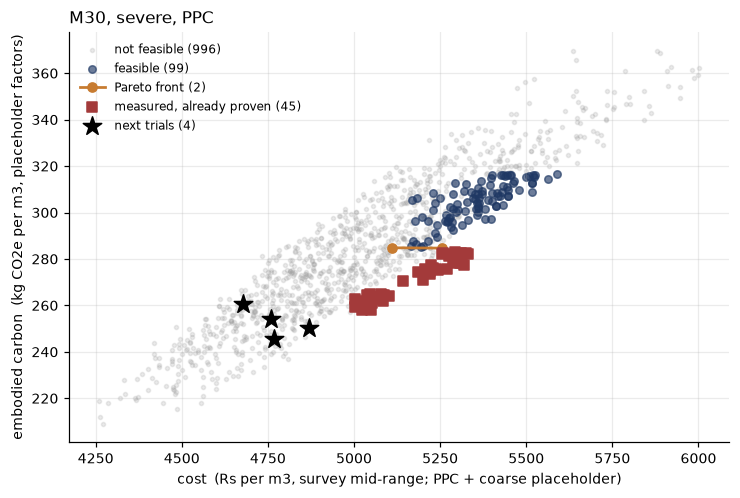

 cement_kg_m3  flyash_kg_m3  ggbs_kg_m3  water_kg_m3  wb_ratio  admixture_kg_m3  fc_pred  P_strength  slump_pred  P_slump  cost_inr_m3  carbon_kg_m3
       403.22         45.35         0.0       147.72      0.33             4.02    47.97        0.96      165.15     0.25      5110.86        284.82
       401.53         47.48         0.0       144.30      0.32             5.49    49.83        0.99      204.54     0.16      5256.61        284.69


In [92]:
front = pareto_front(history)
feas = history[history.feasible]
infe = history[~history.feasible & history.inside_training_range]

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.scatter(infe.cost_inr_m3, infe.carbon_kg_m3, s=7, c=GREY, alpha=0.20, label=f'not feasible ({len(infe)})')
ax.scatter(feas.cost_inr_m3, feas.carbon_kg_m3, s=24, c=NAVY, alpha=0.65, label=f'feasible ({len(feas)})')
if len(front):
    ax.plot(front.cost_inr_m3, front.carbon_kg_m3, '-o', c=AMBER, ms=6, lw=1.8,
            label=f'Pareto front ({len(front)})', zorder=5)
if len(incumbents):
    ax.scatter(incumbents.cost_inr_m3, incumbents.carbon_kg_m3, marker='s', s=40, c=RED,
               label=f'measured, already proven ({len(incumbents)})', zorder=6)
if len(nxt):
    ax.scatter(nxt.cost_inr_m3, nxt.carbon_kg_m3, marker='*', s=160, c='k',
               label=f'next trials ({len(nxt)})', zorder=7)
ax.set_xlabel('cost  (Rs per m3, survey mid-range; PPC + coarse placeholder)')
ax.set_ylabel('embodied carbon  (kg CO2e per m3, placeholder factors)')
ax.set_title(f'{req.grade}, {req.exposure}, {mat.cement_type}', loc='left')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

if len(front):
    print(front[['cement_kg_m3', 'flyash_kg_m3', 'ggbs_kg_m3', 'water_kg_m3', 'wb_ratio',
                 'admixture_kg_m3', 'fc_pred', 'P_strength', 'slump_pred', 'P_slump',
                 'cost_inr_m3', 'carbon_kg_m3']].round(2).to_string(index=False))

## 6. The filter funnel

How many sampled mixes survive each filter. The step with the biggest drop is the binding
constraint — the place where better data or a better model would widen the choice most.

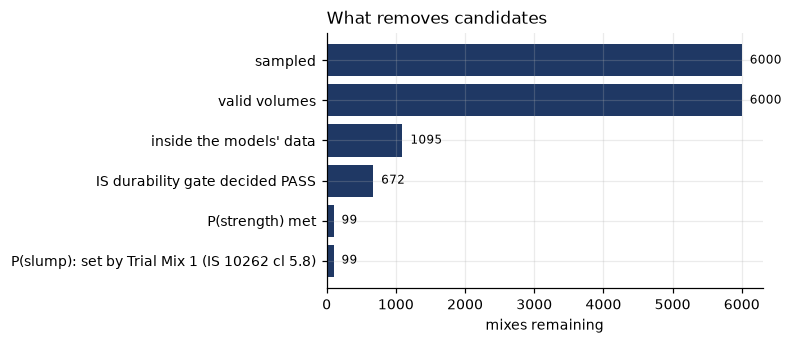

In [93]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.barh(fun.index[::-1], fun.values[::-1], color=NAVY)
for i, v in enumerate(fun.values[::-1]):
    ax.text(v, i, f"  {v}", va='center', fontsize=8)
ax.set_xlabel('mixes remaining'); ax.set_title('What removes candidates', loc='left')
plt.tight_layout(); plt.show()

## 7. The constraint landscape

Which requirement is binding: strength or slump?

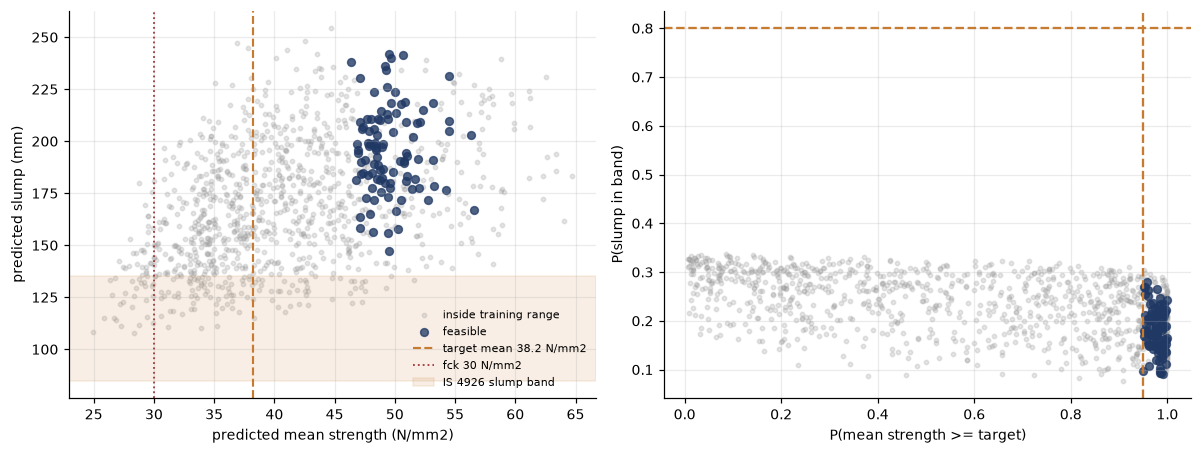

meet strength 236 | meet slump 0
binding: strength -- slump is set by Trial Mix 1 at a new plant (IS 10262 cl 5.8)


In [94]:
inside = history[history.inside_training_range]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.scatter(inside.fc_pred, inside.slump_pred, s=8, c=GREY, alpha=0.25, label='inside training range')
ax.scatter(feas.fc_pred, feas.slump_pred, s=26, c=NAVY, alpha=0.75, label='feasible')
ax.axvline(req.target["target_mean"], c=AMBER, ls='--', lw=1.4, label=f"target mean {req.target['target_mean']:.1f} N/mm2")
ax.axvline(req.fck, c=RED, ls=':', lw=1.2, label=f'fck {req.fck:.0f} N/mm2')
ax.axhspan(*req.slump_band, color=AMBER, alpha=0.12, label='IS 4926 slump band')
ax.set_xlabel('predicted mean strength (N/mm2)'); ax.set_ylabel('predicted slump (mm)')
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
ax.scatter(inside.P_strength, inside.P_slump, s=8, c=GREY, alpha=0.25)
ax.scatter(feas.P_strength, feas.P_slump, s=26, c=NAVY, alpha=0.75)
ax.axvline(req.p_strength_min, c=AMBER, ls='--'); ax.axhline(req.p_slump_min, c=AMBER, ls='--')
ax.set_xlabel('P(mean strength >= target)'); ax.set_ylabel('P(slump in band)')
plt.tight_layout(); plt.show()
n_s = int((inside.P_strength >= req.p_strength_min).sum()); n_w = int((inside.P_slump >= req.p_slump_min).sum())
print(f"meet strength {n_s} | meet slump {n_w}")
print("binding: " + ("strength -- slump is set by Trial Mix 1 at a new plant (IS 10262 cl 5.8)"
                     if not opt.slump_filter else ('slump' if n_w < n_s else 'strength')))

## 8. Uncertainty on the recommended mixes

Each recipe carries a predicted strength with a calibrated 90 % interval (03's
cross-conformal factor). A mix predicted at 39 N/mm2 with a wide interval is a coin flip.

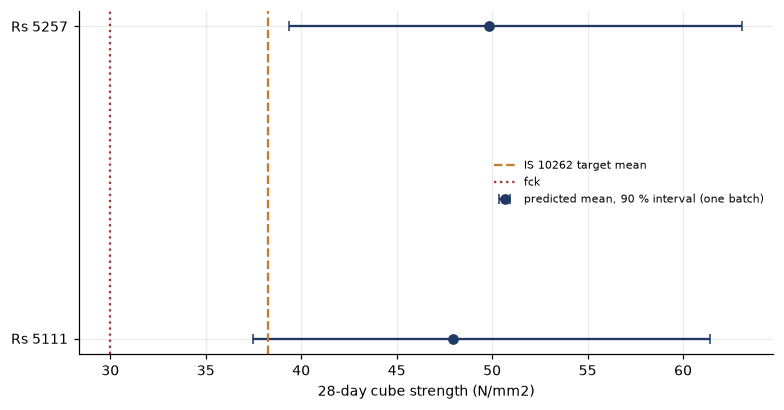

In [95]:
show = front.head(8) if len(front) else history[history.inside_training_range].nlargest(8, 'P_feasible')
if len(show):
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    y = np.arange(len(show))
    ax.errorbar(show.fc_pred, y, xerr=[show.fc_pred - show.fc_lo90, show.fc_hi90 - show.fc_pred],
                fmt='o', c=NAVY, capsize=3, label='predicted mean, 90 % interval (one batch)')
    ax.axvline(req.target["target_mean"], c=AMBER, ls='--', label="IS 10262 target mean")
    ax.axvline(req.fck, c=RED, ls=':', label='fck')
    ax.set_yticks(y); ax.set_yticklabels([f"Rs {c:.0f}" for c in show.cost_inr_m3])
    ax.set_xlabel('28-day cube strength (N/mm2)'); ax.legend(frameon=False, fontsize=7)
    plt.tight_layout(); plt.show()

## 9. Durability report for the cheapest recipe

Every clause the IS gate checked, with its outcome. `not_verified` is honest: it means
the data needed to judge that clause has not been supplied.

In [96]:
pick = front.iloc[0] if len(front) else (nxt.iloc[0] if len(nxt) else None)
if pick is not None:
    g = compliance_gate(cement_kg_m3=pick.cement_kg_m3, fly_ash_kg_m3=pick.flyash_kg_m3,
                        ggbs_kg_m3=pick.ggbs_kg_m3, other_scm_kg_m3=0.0,
                        free_water_kg_m3=pick.free_water_for_gate, grade=req.grade,
                        exposure=req.exposure, use=req.use, msa_mm=req.msa_mm,
                        cement_type=mat.cement_type,
                        ppc_fly_ash_declared_pct=mat.ppc_fly_ash_declared_pct,
                        sulphate_class_=req.sulphate_class, sea_water=req.sea_water,
                        freeze_thaw=req.freeze_thaw, volume_closure_m3=pick.volume_m3,
                        admixture_kg_m3=pick.admixture_kg_m3,
                        admixture_dosage_range_pct=mat.admixture_dosage_range_pct)
    print(pd.DataFrame(g["checks"])[["clause", "check", "outcome"]].to_string(index=False))

                                    clause                           check      outcome
                         IS 456 cl 8.2.4.2                  maximum cement         pass
         IS 456 Table 5 + Table 6 + Note 1                  minimum binder         pass
IS 456 Table 5 + Note 1; IS 10262 cl 5.1.2                maximum free w/c         pass
                           IS 456 cl 6.1.2                   minimum grade         pass
                            IS 456 Table 7              chloride (Table 7) not_verified
                         IS 456 cl 8.2.5.3                      SO3 in mix not_verified
                           IS 456 cl 9.1.1             design mix required         pass
                           IS 10262 cl 5.7                  volume closure         pass
                          IS 10262 Table 9                      SCM dosage         pass
                           IS 456 cl 5.5.1 admixture complies with IS 9103 not_verified
                           IS 91

## 10. The recommendation

The output is a **portfolio** plus the **next trials**. Nothing here is production-approved.

In [97]:
label = ("COMPUTATIONALLY COMPLIANT" if MATERIALS_VERIFIED
         else "COMPUTATIONALLY COMPLIANT -- ASSUMES MATERIALS CONFORM TO THEIR IS")

def describe(m, tag):
    print(f"\n{tag}")
    print(f"  {mat.cement_type} {m.cement_kg_m3:6.0f}   fly ash {m.flyash_kg_m3:5.0f}   GGBS {m.ggbs_kg_m3:5.0f}   "
          f"water {m.water_kg_m3:5.0f}   admixture {m.admixture_kg_m3:4.1f}   (kg/m3)")
    print(f"  crushed sand {m.crushed_sand_kg_m3:5.0f}   coarse {m.coarse_agg_kg_m3:5.0f}   w/b {m.wb_ratio:.3f}")
    print(f"  strength {m.fc_pred:5.1f} N/mm2 (90 % {m.fc_lo90:.1f}-{m.fc_hi90:.1f}),  P(mean >= {req.target['target_mean']:.1f}) {m.P_strength:.2f}")
    print(f"  slump    {m.slump_pred:5.0f} mm  (90 % {m.slump_lo90:.0f}-{m.slump_hi90:.0f}),  P(in band) {m.P_slump:.2f}")
    print(f"  cost Rs {m.cost_inr_m3:,.0f}/m3   carbon {m.carbon_kg_m3:.0f} kg/m3   status: {label}")

if len(front):
    describe(front.sort_values('cost_inr_m3').iloc[0], "CHEAPEST FEASIBLE")
    describe(front.sort_values('carbon_kg_m3').iloc[0], "LOWEST CARBON FEASIBLE")
    out = front.copy(); out["status"] = label
    out.to_csv("pareto_portfolio.csv", index=False)
    print(f"\nsaved pareto_portfolio.csv ({len(out)} recipes)")

    # does the cheapest recipe depend on where in the survey ranges the real rates fall?
    feas_ = history[history.feasible]
    print("\ncost of the feasible set at the low / mid / high end of the survey ranges:")
    for b in ("low", "mid", "high"):
        mb = Materials(**{**mat.__dict__, "cost": rates_from_survey(b)})
        c_ = np.array([cost_carbon(r, mb)[0] for r in feas_.to_dict("records")])
        i_ = int(np.argmin(c_))
        print(f"  {b:4s}: cheapest Rs {c_[i_]:,.0f}/m3  ({feas_.cement_kg_m3.iloc[i_]:.0f} {mat.cement_type}"
              f" + {feas_.flyash_kg_m3.iloc[i_]:.0f} fly ash)")
else:
    print("no feasible recipe -- see the funnel in section 6 for the binding filter")

if len(nxt):
    ne = nxt.copy()
    ne.insert(0, "trial_id", [f"T{i+1}" for i in range(len(ne))])
    ne["status"] = label
    # human-in-the-loop: kept separate from measured results (project methodology)
    ne["review_decision"] = ""          # accept / reject, BEFORE casting
    ne["rejection_reason"] = ""         # one of the eight, below
    ne["measured_slump_mm"] = ""        # after casting -- IS 1199 (Part 2)
    ne["measured_fc_28d_mpa"] = ""      # after 28 days -- IS 516, cl 15.4 sample result
    ne["measured_fc_7d_mpa"] = ""       # optional, IS 456 cl 15.1.1 (steering only)
    ne.to_csv("next_experiments.csv", index=False)
    print(f"saved next_experiments.csv ({len(ne)} trials to review)")
    # prospective record: every proposal is appended with its predictions, BEFORE any result
    # exists, so 08b can later test the predictions honestly (no hindsight).
    run_id = pd.Timestamp.now().strftime("%Y%m%d-%H%M%S")
    log = ne.assign(run_id=run_id, plant_id=PLANT_ID, grade=req.grade, exposure=req.exposure,
                    target_mean=req.target["target_mean"], S_used=req.target["S"],
                    S_basis=req.target["S_basis"], slump_target_mm=req.slump_target_mm,
                    cement_type=mat.cement_type, msa_mm=req.msa_mm)
    log["trial_id"] = run_id + "-" + log["trial_id"]
    import os
    if os.path.exists(TRIAL_LOG):                 # re-running 08 must not log the same trial twice
        old = pd.read_csv(TRIAL_LOG)
        seen = set(map(trial_key, old.to_dict("records")))
        dup = log.apply(lambda r: trial_key(r.to_dict()) in seen, axis=1)
        log = log[~dup]
    if len(log):
        log.to_csv(TRIAL_LOG, mode="a", header=not os.path.exists(TRIAL_LOG), index=False)
    print(f"{TRIAL_LOG}: {len(log)} new proposal(s) appended (run {run_id}); "
          f"{len(ne) - len(log)} already logged by an earlier run. Fill measured_* after casting.")


CHEAPEST FEASIBLE
  PPC    403   fly ash    45   GGBS     0   water   148   admixture  4.0   (kg/m3)
  crushed sand   661   coarse  1174   w/b 0.329
  strength  48.0 N/mm2 (90 % 37.5-61.4),  P(mean >= 38.2) 0.96
  slump      165 mm  (90 % 72-380),  P(in band) 0.25
  cost Rs 5,111/m3   carbon 285 kg/m3   status: COMPUTATIONALLY COMPLIANT -- ASSUMES MATERIALS CONFORM TO THEIR IS

LOWEST CARBON FEASIBLE
  PPC    402   fly ash    47   GGBS     0   water   144   admixture  5.5   (kg/m3)
  crushed sand   803   coarse  1032   w/b 0.321
  strength  49.8 N/mm2 (90 % 39.4-63.1),  P(mean >= 38.2) 0.99
  slump      205 mm  (90 % 92-456),  P(in band) 0.16
  cost Rs 5,257/m3   carbon 285 kg/m3   status: COMPUTATIONALLY COMPLIANT -- ASSUMES MATERIALS CONFORM TO THEIR IS

saved pareto_portfolio.csv (2 recipes)

cost of the feasible set at the low / mid / high end of the survey ranges:
  low : cheapest Rs 3,955/m3  (403 PPC + 45 fly ash)
  mid : cheapest Rs 5,111/m3  (403 PPC + 45 fly ash)
  high: che

## 11. Same requirement, OPC instead of PPC

India uses both. The IS thresholds change with cement type (fly ash counting, Table 4,
soundness standard). This re-runs the same search with OPC so the two can be compared.
**OPC conformity and soundness stay NOT VERIFIED**: IS 269 : 2015 is not in the folder.

Both cements go through the same models: OPC directly, PPC as OPC + 35 % fly ash (03b).
So the difference below comes from the cement's make-up and the IS rules, not from which
plant happened to use which cement.

In [98]:
mat_opc = Materials(cement_type="OPC", has_flyash=True, has_ggbs=False)
opt_opc = SDLOptimiser(sm, wm, req, mat_opc, TRANSFER, DOMAIN, PLANT_RESULTS, EARLY)
X1, _ = opt_opc.seed(n=6000)
h_opc = opt_opc.evaluate(X1)
rows = []
for name, h, m in (("PPC", history, mat), ("OPC", h_opc, mat_opc)):
    f = pareto_front(h)
    o = opt if name == "PPC" else opt_opc
    rows.append({"cement": name, **dict(zip(["sampled", "valid", "inside data", "IS gate PASS",
                                              "P(strength) met", "final"],
                                             o.funnel(len(X0), h).values)),
                 "cheapest Rs/m3": round(f.cost_inr_m3.min()) if len(f) else None,
                 "lowest carbon kg/m3": round(f.carbon_kg_m3.min()) if len(f) else None,
                 "conformity": check_cement(name, m.cement_cert or {})["conforms"]})
print(pd.DataFrame(rows).set_index("cement").T.to_string())

cement                PPC   OPC
sampled              6000  6000
valid                6000  6000
inside data          1095  1311
IS gate PASS          672  1097
P(strength) met        99   395
final                  99   395
cheapest Rs/m3       5111  4616
lowest carbon kg/m3   285   243
conformity           None  None


## 12. Example — the same search after 3 trials at one plant

This shows the general model adjusting to a plant. Three measured PPC batches from the
data stand in for three trials cast at that plant. Nothing else changes.

*Illustration only:* these three batches were also in 03's training data, so this shows the
mechanism, not an independent test. The independent test is 03b's leave-one-plant-out.

In [99]:
d = pd.read_csv("01_RAW_dataset.csv", low_memory=False)
num = lambda c: pd.to_numeric(d[c], errors="coerce")
pic = d[(d.plant_lab_id.astype(str) == "Plant D") & (d.grade.astype(str) == req.grade)].head(3)
EXAMPLE = []
for i in pic.index:
    cubes = [num(f"cube_28d_{j}")[i] for j in (1, 2, 3)]
    s = sample_test_result(cubes)                         # IS 456 cl 15.4
    coarse = sum(float(np.nan_to_num(num(k)[i])) for k in ("agg_40mm", "agg_20mm", "agg_10mm", "agg_other"))
    EXAMPLE.append({"mix": {"cement": num("cement")[i], "flyash": float(np.nan_to_num(num("flyash")[i])),
                            "ggbs": 0.0, "other_scm": 0.0, "water": num("water_batched")[i],
                            "coarse_agg": coarse, "crushed_sand": float(np.nan_to_num(num("crushed_sand")[i])),
                            "natural_sand": float(np.nan_to_num(num("natural_sand")[i])),
                            "admixture": float(np.nan_to_num(num("admixture1")[i])), "msa": 20,
                            "cement_type": "PPC"},
                    "fc_28d": s["result_mpa"], "slump_mm": num("slump")[i],
                    "fc_7d_cubes": [num(f"cube_7d_{j}")[i] for j in (1, 2, 3)]})
req3 = Requirement(**{**req.__dict__, "p_slump_min": 0.80})
opt3 = SDLOptimiser(sm, wm, req3, mat, TRANSFER, DOMAIN, EXAMPLE, EARLY)
h3 = opt3.evaluate(X0)
for name, o in (("strength", opt3.off_s), ("slump", opt3.off_w)):
    print(f"{name:8s}: {o['k']} results -> offset {o['offset']:+.3f} (log, {np.expm1(o['offset'])*100:+.0f} %), "
          f"remaining plant sd {np.sqrt(o['var']):.3f} (was {np.sqrt(TRANSFER['tau']['fc' if name == 'strength' else 'slump_mm']['tau_log']**2):.3f})")
f0, f3 = pareto_front(history), pareto_front(h3)
print(pd.DataFrame({"new plant (general)": opt.funnel(len(X0), history).values,
                    "after 3 trials here": opt3.funnel(len(X0), h3).values},
                   index=FUNNEL_STEPS[:-1] + ["P(slump) met / set by Trial 1"]).to_string())
print(f"cheapest feasible: general Rs {f0.cost_inr_m3.min() if len(f0) else float('nan'):.0f}"
      f"  ->  after 3 trials Rs {f3.cost_inr_m3.min() if len(f3) else float('nan'):.0f}")

# The same three trials seen at DAY 7 only (IS 456 cl 15.1.1: steering, never acceptance)
EX7 = [{"mix": e["mix"], "slump_mm": e["slump_mm"],
        "fc_7d": sample_test_result(e["fc_7d_cubes"])["result_mpa"]} for e in EXAMPLE]
o7 = plant_offset(sm, TRANSFER["tau"]["fc"]["tau_log"], EX7, "fc_28d", TRANSFER["ppc_model_x_pct"], EARLY)
print(f"\nday 7 only : strength offset {o7['offset']:+.3f} (log), plant sd {np.sqrt(o7['var']):.3f}"
      f"   | day 28: {opt3.off_s['offset']:+.3f}, sd {np.sqrt(opt3.off_s['var']):.3f}"
      f"   | none: 0, sd {TRANSFER['tau']['fc']['tau_log']:.3f}")

strength: 3 results -> offset +0.073 (log, +8 %), remaining plant sd 0.038 (was 0.100)
slump   : 3 results -> offset -0.572 (log, -44 %), remaining plant sd 0.052 (was 0.430)
                                 new plant (general)  after 3 trials here
sampled                                         6000                 6000
valid volumes                                   6000                 6000
inside the models' data                         1095                 1095
IS durability gate decided PASS                  672                  672
P(strength) met                                   99                  309
P(slump) met / set by Trial 1                     99                   23
cheapest feasible: general Rs 5111  ->  after 3 trials Rs 5002

day 7 only : strength offset +0.033 (log), plant sd 0.059   | day 28: +0.073, sd 0.038   | none: 0, sd 0.100


## 13. At a plant with its own record — IS 10262 cl 4.2.1

**The standard** (IS 10262:2019, read from the PDF, page 4):

* cl 4.2.1.1 (a): an acceptable record for calculating S has **not less than 30** sample results.
* cl 4.2.1.2.1: S = √(Σ(Xᵢ − X̄)² / (n − 1)); cl 4.2.1.2.2 pools two groups (each ≥ 10, total ≥ 30).
* cl 4.2.1.3: Table 2 S "may be assumed ... in the first instance. **As soon as the results of
  samples are available, actual calculated standard deviation shall be used**".
* cl 4.2.1.1 (b): after a significant change (materials source, mix proportioning, equipment,
  technical control) S is calculated separately. (c): S is checked every month on at least 30
  results; if it rises above the value used in design, the mix must be modified.

So at a plant with a record, the **established** S is not a relaxation — it is what the
standard requires. The example below uses one plant's M30 record from the data.

In [100]:
d = pd.read_csv("01_RAW_dataset.csv", low_memory=False)
d["_date"] = pd.to_datetime(d.batch_date, errors="coerce")
rec = d[(d.plant_lab_id.astype(str) == "Plant D") & (d.grade.astype(str) == req.grade)]
rec = rec.sort_values(["_date", "batch_no"])                   # consecutive, in the order cast
cubes = rec[["cube_28d_1", "cube_28d_2", "cube_28d_3"]].apply(pd.to_numeric, errors="coerce").values
record = [r["result_mpa"] for r in map(sample_test_result, cubes.tolist()) if r["valid"]]
print(f"record: {len(record)} valid sample results (IS 456 cl 15.4), {rec.design_id.nunique()} design, "
      f"{rec._date.min():%d %b %Y} - {rec._date.max():%d %b %Y}, mean {np.mean(record):.2f} N/mm2")

est = established_standard_deviation([record], req.grade)           # IS 10262 cl 4.2.1.1 / 4.2.1.2
req_s = Requirement(**{**req.__dict__, "established_s": est["S"], "n_results": est["n_results"]})
t0_, t1_ = req.target, req_s.target
print(f"S assumed (Table 2)  {t0_['S']:.2f} -> target mean {t0_['target_mean']:.2f} ({t0_['binding']})")
print(f"S established        {t1_['S']:.2f} -> target mean {t1_['target_mean']:.2f} ({t1_['binding']})   [{est['source']}]")
chk = standard_deviation_check(record[-30:], t0_["S"])              # cl 4.2.1.1 (c)
print(f"monthly check, cl 4.2.1.1 (c): {chk['outcome']} -- {chk['detail']}")

acc = acceptance_is456(record, req.grade, established_s=est["S"])  # IS 456 cl 16.1 / Table 11
bad = [g_ for g_ in acc["groups"] if not g_["ok"]]
print(f"IS 456 cl 16.1 on this record: mean-of-4 >= {acc['limits']['mean_of_4_min']:.1f}: "
      f"{len(acc['groups']) - len(bad)}/{len(acc['groups'])} groups pass; individual >= "
      f"{acc['limits']['individual_min']:.1f}: {acc['individual_criterion']}")

opt_s = SDLOptimiser(sm, wm, req_s, mat, TRANSFER, DOMAIN, EXAMPLE, EARLY)
h_s = opt_s.evaluate(X0)
f3_, fs_ = pareto_front(h3), pareto_front(h_s)
inc_s = measured_incumbents("01_RAW_dataset.csv", req_s, mat)
print(pd.DataFrame({"3 trials, S assumed": opt3.funnel(len(X0), h3).values,
                    "3 trials, S established": opt_s.funnel(len(X0), h_s).values},
                   index=FUNNEL_STEPS[:-1] + ["P(slump) met / set by Trial 1"]).to_string())
print(f"cheapest feasible: S assumed Rs {f3_.cost_inr_m3.min() if len(f3_) else float('nan'):,.0f}"
      f"  ->  S established Rs {fs_.cost_inr_m3.min() if len(fs_) else float('nan'):,.0f}")
print(f"measured mixes meeting the target: {len(measured_incumbents('01_RAW_dataset.csv', req, mat))} "
      f"(S assumed) -> {len(inc_s)} (S established)")

record: 82 valid sample results (IS 456 cl 15.4), 1 design, 01 May 2026 - 31 Aug 2026, mean 35.83 N/mm2
S assumed (Table 2)  5.00 -> target mean 38.25 (1.65S)
S established        2.75 -> target mean 36.50 (X floor)   [IS 10262 cl 4.2.1.1 (a) + 4.2.1.2.1]
monthly check, cl 4.2.1.1 (c): pass -- S of last 30 results 2.78 vs 5.00 used in design
IS 456 cl 16.1 on this record: mean-of-4 >= 34.0: 18/20 groups pass; individual >= 26.0: pass
                                 3 trials, S assumed  3 trials, S established
sampled                                         6000                     6000
valid volumes                                   6000                     6000
inside the models' data                         1095                     1095
IS durability gate decided PASS                  672                      672
P(strength) met                                  309                      384
P(slump) met / set by Trial 1                     23                       26
cheapest feasibl

**Read this before using an established S.** The record's own mean can sit below the
IS 10262 target mean, and a lower target leaves less margin against IS 456 cl 16.1
acceptance (groups of four). If any group of four in the record fails the mean-of-4
limit above, the plant's variability is already close to the acceptance edge: an engineer
decides whether to design to the lower target. The SDL reports it; it does not decide it.

---

### What to do with the output

1. **Review before casting.** An engineer accepts or rejects each row of
   `next_experiments.csv`. A rejection records **one reason**, kept separate:
   human rejection before experiment · physical experimental failure · measured workability ·
   measured strength · material availability · cost · constructability · other.
   A rejection without a cast is **not** training data.
2. **Cast the accepted trials.** Slump by IS 1199 (Part 2) — a sheared or collapsed slump is
   not a result. Three cubes per sample; a sample is valid only if every cube is within
   ±15 % of the mean (IS 456 cl 15.4).
3. **Add the measured results to the data, re-run 03, then re-run this notebook.** That is
   one turn of the Bayesian loop.
4. **Status ladder.** Everything this notebook prints is *computationally compliant*.
   A cast makes it *laboratory validated*; a plant trial batch makes it *trial-batch
   validated*; routine production against IS 456 Table 11 makes it *production validated*.
5. **Plant adjustment.** After each cast at a plant, fill `measured_*` for that trial in
   `trial_log.csv` (set `PLANT_ID`), or add it to `PLANT_RESULTS`, and re-run. The first slump switches the slump
   filter on for that plant (IS 10262 cl 5.8); more results shrink the plant spread.
   **Day 7:** the 7-day result (`fc_7d`) may be added first so the next batch can be chosen
   three weeks sooner. It counts for less than a 28-day result, it is replaced by the
   28-day result when that arrives, and it is **never** used to accept a mix — IS 456
   cl 15.1.1: the 28-day strength "shall alone be the criterion for acceptance or rejection".
6. **Plant record.** If the plant has ≥ 30 consecutive valid results for this grade since its
   last significant change, put them in `PLANT_RECORD`: IS 10262 cl 4.2.1.3 then requires the
   calculated S (section 13), and cl 4.2.1.1 (c) requires a monthly re-check.
7. **Stopping.** 08 proposes nothing when the best expected gain is below 1 % of what the
   measured mixes already achieve (`STOP_REL_EHVI`, after Jones et al. 1998). Fewer than four
   proposals, or none, means more trials are not expected to pay.
8. **General by default.** Materials are assumed to conform to their Indian Standards and
   PPC is taken at the IS 1489 maximum of 35 % fly ash. A plant using this later can supply
   its certificates (PPC declared fly ash %, IS 1489 cl 9.1; fly ash, GGBS, aggregate tests;
   chloride and SO3 of every constituent) and its own rates. Rates are the project's
   market survey (mid-range, bulk, delivered); PPC, coarse aggregate and water rates and
   all carbon factors are still placeholders.